<a href="https://colab.research.google.com/github/imguru-mooc/AI_CAMPUS/blob/main/NN-day3/NN_Day3_lecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Neural Network Day 3 — 역전파 (backpropagation)

**온디바이스 AI · Neural Network 3/5 · 10/22(목)** · Google Colab · Python + NumPy

어제(Day 2) 신경망의 **몸체** — 순전파 $Y = XW + b$ 와 손실 — 를 만들고, 로지스틱 회귀의 기울기 $X^\top(P - T)/N$ 을 손으로 유도했습니다. 그런데 층이 쌓이면 손 유도는 어렵고, 수치 미분은 MNIST 망에서 step 한 번에 손실을 **159,020번** 계산해야 했습니다. 오늘은 **계산 그래프**와 **연쇄 법칙**으로 모든 기울기를 순전파 한 번 + 역방향 한 번에 구하는 **역전파**를 만들고, 그것으로 MNIST 손글씨 숫자를 **95% 이상** 맞히는 신경망을 학습시킵니다.

| 교시 | 주제 | 애니메이션 |
|---|---|---|
| 1 | 복습 퀴즈 · 수치 미분의 한계 | D3-1 |
| 2 | 계산 그래프 | D3-2 |
| 3 | 연쇄 법칙 — 덧셈 · 곱셈 노드 | D3-3 |
| 4 | 활성화 계층 — ReLU · Sigmoid | D3-4 |
| 5 | Affine · Softmax-with-Loss 계층 | D3-5 · D3-6 |
| 6 | Gradient check | D3-7 |
| 7 | 미니배치 SGD — 나선 데이터 | D3-8 |
| 8 | 미니 프로젝트 — MNIST 2층 MLP (이 노트북 맨 끝) | D3-9 |

### 📚 오늘의 온라인 자료

| 자료 | 링크 |
|---|---|
| 🎬 애니메이션 (시뮬레이션 9개) | [https://imguru-mooc.github.io/AI_CAMPUS/NN-day3/animation.html](https://imguru-mooc.github.io/AI_CAMPUS/NN-day3/animation.html) |
| 📝 개념 워크시트 (8교시 × 10문항) | [https://imguru-mooc.github.io/AI_CAMPUS/NN-day3/worksheet.html](https://imguru-mooc.github.io/AI_CAMPUS/NN-day3/worksheet.html) |
| 🖥 슬라이드 (PDF) | [https://imguru-mooc.github.io/AI_CAMPUS/NN-day3/NN_Day3.pdf](https://imguru-mooc.github.io/AI_CAMPUS/NN-day3/NN_Day3.pdf) |

**노트북 사용법**

1. `____` 가 있는 셀은 빈칸을 채운 뒤 실행합니다.
2. 바로 아래 **확인 셀**이 `✅` 를 출력하면 정답입니다. `AssertionError` 가 나면 다시 생각해 보세요.
3. 막히면 그 아래 **🔒 정답 보기** 셀을 실행하면 정답 코드와 해설이 출력됩니다. 먼저 스스로 풀어 본 뒤에 여세요.
4. 맨 위 **환경 셀**은 Day 1 · 2 의 도구(`numerical_gradient`, `softmax` …)를 다시 만들고 MNIST(약 11 MB)를 내려받습니다. 런타임이 끊기면 환경 셀부터 다시 실행하세요.
5. 오늘 만드는 계층 클래스(`MulLayer` → `Relu` → `Affine` → `SoftmaxWithLoss` → `TwoLayerNet`)는 **앞에서 만든 것을 뒤에서 그대로 씁니다**. 위에서부터 순서대로 실행하세요.

In [ ]:
# ▶ 환경 셀 — 런타임이 끊기면 이 셀부터 다시 실행하세요
import os, gzip, pickle, time, urllib.request
from collections import OrderedDict
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (5, 4)    # 그래프 글자는 영어로 씁니다 (Colab 기본 글꼴에 한글이 없음)

try:                                      # Colab 에서만 Drive 연결
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Colab 이 아닌 환경 — Drive 마운트 생략")

# ── Day 1 · Day 2 에서 만든 도구 (그대로 다시 씁니다) ──
def numerical_gradient(f, x, h=1e-4):
    """중앙 차분으로 f 의 기울기를 구한다. x 는 실수 배열(어떤 shape 든), 원래 값으로 되돌려 놓는다."""
    grad = np.zeros_like(x)
    it = np.nditer(x, flags=["multi_index"])
    while not it.finished:
        idx = it.multi_index
        orig = x[idx]
        x[idx] = orig + h;  fxh1 = f(x)
        x[idx] = orig - h;  fxh2 = f(x)
        grad[idx] = (fxh1 - fxh2) / (2 * h)
        x[idx] = orig
        it.iternext()
    return grad

def sigmoid(a):
    return 1 / (1 + np.exp(-a))

def relu(a):
    return np.maximum(0, a)

def softmax(A):
    A = A - A.max(axis=-1, keepdims=True)
    expA = np.exp(A)
    return expA / expA.sum(axis=-1, keepdims=True)

def one_hot(t, num_classes=10):
    return np.eye(num_classes)[t]

def cross_entropy(y, t):                  # Day 2 버전 (t 는 one-hot, log 에 1e-7)
    if y.ndim == 1:
        y, t = y.reshape(1, -1), t.reshape(1, -1)
    return -np.sum(t * np.log(y + 1e-7)) / y.shape[0]

# ── MNIST 손글씨 숫자 (8교시 · 6교시에서 사용) ──
def load_mnist(path="mnist.npz"):
    """mnist.npz 를 내려받아 (x_train, y_train), (x_test, y_test) 를 돌려준다. 기본 주소가 막히면 GitHub 사본을 쓴다."""
    if not os.path.exists(path):
        try:
            urllib.request.urlretrieve("https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz", path)
        except Exception as e:
            print("기본 주소 실패 → GitHub 사본에서 받습니다:", e)
            urllib.request.urlretrieve("https://raw.githubusercontent.com/mnielsen/neural-networks-and-deep-learning/master/data/mnist.pkl.gz", "mnist.pkl.gz")
            tr, va, te = pickle.load(gzip.open("mnist.pkl.gz"), encoding="latin1")
            to_u8 = lambda a: np.round(a * 256).astype(np.uint8).reshape(-1, 28, 28)
            np.savez_compressed(path, x_train=to_u8(np.concatenate([tr[0], va[0]])),
                                y_train=np.concatenate([tr[1], va[1]]).astype(np.uint8),
                                x_test=to_u8(te[0]), y_test=te[1].astype(np.uint8))
    d = np.load(path)
    return (d["x_train"], d["y_train"]), (d["x_test"], d["y_test"])

(x_train, y_train), (x_test, y_test) = load_mnist()
print("NumPy", np.__version__, "| MNIST", x_train.shape, y_train.shape, x_test.shape, y_test.shape)

## 1교시 — 복습 퀴즈 · 수치 미분의 한계

**09:00 ~ 09:15 Day 2 복습 퀴즈** — 강사가 공유하는 Google Forms 링크로 20문항을 풉니다. 제출하면 점수와 해설이 바로 나옵니다.

### 수치 미분은 왜 느린가

> 🎬 **애니메이션** [D3-1 수치 미분 vs 역전파 비용](https://imguru-mooc.github.io/AI_CAMPUS/NN-day3/animation.html#d3-1)  
> 📝 **워크시트** [1교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day3/worksheet.html#t1)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

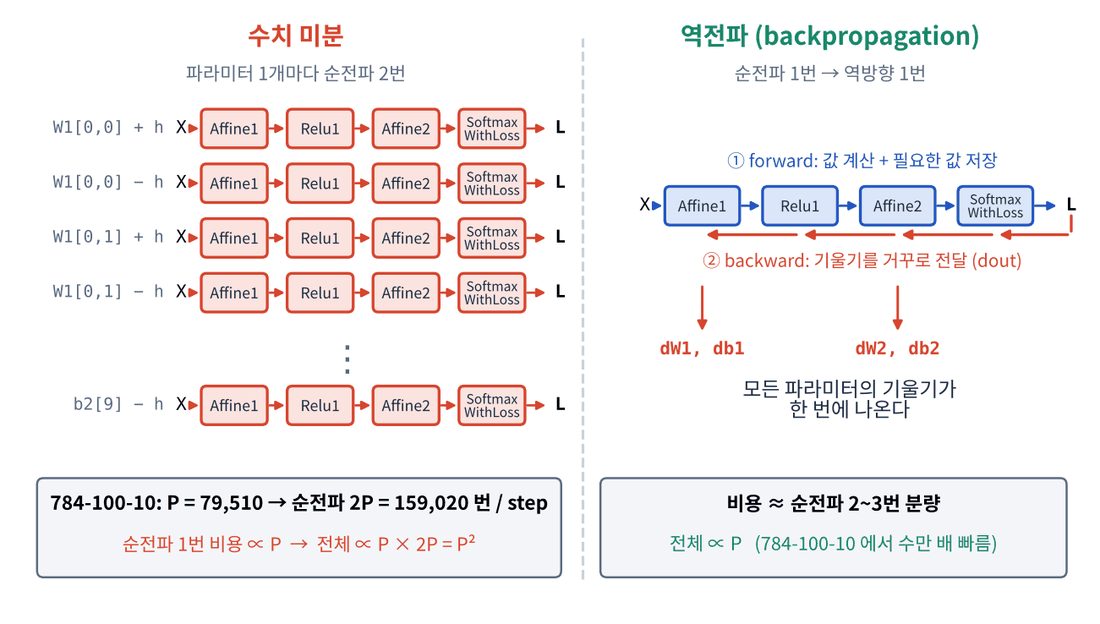

Day 1 의 수치 미분은 파라미터 **하나**를 $\pm h$ 만큼 움직여 손실을 **두 번** 계산합니다.

$$\frac{\partial L}{\partial W_{ij}} \approx \frac{L(W_{ij} + h) - L(W_{ij} - h)}{2h}$$

파라미터가 $P$ 개면 step 한 번에 순전파를 $2P$ 번 합니다. 그런데 순전파 한 번의 비용도 대부분 행렬곱이라 $P$ 에 비례합니다. 그래서

$$\text{수치 미분 1 step 비용} \;\propto\; 2P \times P \;=\; O(P^2)$$

파라미터가 10배 늘면 시간은 **100배** 늘어납니다. 반면 오늘 만들 **역전파**는 순전파 한 번 + 역방향 한 번(비용은 순전파의 2~3배)으로 **모든** 기울기를 얻습니다 — $O(P)$.

먼저 Day 2 방식(함수 + 딕셔너리)으로 784-h-10 신경망을 만들어 직접 재 봅니다.

In [ ]:
def init_params(hidden, seed=0):
    rng_ = np.random.default_rng(seed)
    return {"W1": 0.01 * rng_.standard_normal((784, hidden)), "b1": np.zeros(hidden),
            "W2": 0.01 * rng_.standard_normal((hidden, 10)),  "b2": np.zeros(10)}

def loss_fn(params, X, T):                 # Day 2 의 순전파 + cross-entropy
    H = relu(X @ params["W1"] + params["b1"])
    Y = softmax(H @ params["W2"] + params["b2"])
    return cross_entropy(Y, T)

Xm = x_train[:100].reshape(100, -1) / 255.0          # 100장, (100, 784)
Tm = one_hot(y_train[:100])                           # (100, 10)
print("784-4-10 학습 전 손실:", loss_fn(init_params(4), Xm, Tm))

**문제 1-1 · 1-2** 파라미터 수 $P$ 를 세는 함수와, 수치 미분 1 step 에 필요한 손실 계산 횟수를 쓰세요.

In [ ]:
def count_params(params):
    return ____

def n_loss_evals(P):
    return ____                         # 파라미터마다 +h, -h 두 번

In [ ]:
for h in [1, 2, 4, 100]:
    P = count_params(init_params(h))
    print(f"784-{h}-10 : 파라미터 {P:>6,}개 → 수치 미분 1 step 손실 계산 {n_loss_evals(P):>7,}번")
assert count_params(init_params(1)) == 805 and count_params(init_params(100)) == 79_510
assert n_loss_evals(79_510) == 159_020; print("✅")

In [ ]:
#@title 🔒 정답 보기 1-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTEg4pSA4pSACmRlZiBjb3VudF9wYXJhbXMocGFyYW1zKToKICAgIHJldHVybiBzdW0o"
    "cC5zaXplIGZvciBwIGluIHBhcmFtcy52YWx1ZXMoKSkKCmRlZiBuX2xvc3NfZXZhbHMoUCk6CiAgICByZXR1cm4g"
    "MiAqIFAgICAgICAgICAgICAgICAgICAgICAgICAgIyDtjIzrnbzrr7jthLDrp4jri6QgK2gsIC1oIOuRkCDrsog="
).decode("utf-8"))

**문제 1-3** 은닉 뉴런 1 · 2 · 4 개짜리 망에서 수치 미분 1 step 시간을 재고, 784-**100**-10 망의 시간을 추정하세요. 손실 한 번 시간 × 손실 계산 횟수 로 추정합니다. (몇 초 걸립니다)

In [ ]:
times = {}
for h in [1, 2, 4]:
    params = init_params(h)
    t0 = time.perf_counter()
    for k in params:                                             # 모든 파라미터의 수치 미분
        numerical_gradient(lambda _: loss_fn(params, Xm, Tm), params[k])
    times[count_params(params)] = time.perf_counter() - t0

params100 = init_params(100)
t0 = time.perf_counter()
for _ in range(20):
    loss_fn(params100, Xm, Tm)
t_loss = (time.perf_counter() - t0) / 20                           # 784-100-10 손실 한 번 시간
est_100 = ____       # 수치 미분 1 step 추정 시간

In [ ]:
for P, sec in times.items():
    print(f"P = {P:>5,}  수치 미분 1 step {sec:6.3f} 초")
print(f"\n784-100-10 (P = 79,510): 손실 1회 {t_loss * 1000:.2f} ms × 159,020번 ≈ {est_100:.0f} 초 / step")
print(f"MNIST 1 epoch = 600 step → 약 {est_100 * 600 / 3600:.1f} 시간  (10 epoch 이면 {est_100 * 6000 / 3600:.0f} 시간)")
assert est_100 > 5; print("✅")
plt.loglog(list(times), list(times.values()), "o-"); plt.xlabel("parameters P"); plt.ylabel("seconds / step"); plt.grid(alpha=.3, which="both"); plt.title("numerical gradient cost"); plt.show()

In [ ]:
#@title 🔒 정답 보기 1-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTIg4pSA4pSACnRpbWVzID0ge30KZm9yIGggaW4gWzEsIDIsIDRdOgogICAgcGFyYW1z"
    "ID0gaW5pdF9wYXJhbXMoaCkKICAgIHQwID0gdGltZS5wZXJmX2NvdW50ZXIoKQogICAgZm9yIGsgaW4gcGFyYW1z"
    "OiAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICMg66qo65OgIO2MjOudvOuvuO2E"
    "sOydmCDsiJjsuZgg66+467aECiAgICAgICAgbnVtZXJpY2FsX2dyYWRpZW50KGxhbWJkYSBfOiBsb3NzX2ZuKHBh"
    "cmFtcywgWG0sIFRtKSwgcGFyYW1zW2tdKQogICAgdGltZXNbY291bnRfcGFyYW1zKHBhcmFtcyldID0gdGltZS5w"
    "ZXJmX2NvdW50ZXIoKSAtIHQwCgpwYXJhbXMxMDAgPSBpbml0X3BhcmFtcygxMDApCnQwID0gdGltZS5wZXJmX2Nv"
    "dW50ZXIoKQpmb3IgXyBpbiByYW5nZSgyMCk6CiAgICBsb3NzX2ZuKHBhcmFtczEwMCwgWG0sIFRtKQp0X2xvc3Mg"
    "PSAodGltZS5wZXJmX2NvdW50ZXIoKSAtIHQwKSAvIDIwICAgICAgICAgICAgICAgICAgICAgICAgICAgIyA3ODQt"
    "MTAwLTEwIOyGkOyLpCDtlZwg67KIIOyLnOqwhAplc3RfMTAwID0gdF9sb3NzICogbl9sb3NzX2V2YWxzKGNvdW50"
    "X3BhcmFtcyhwYXJhbXMxMDApKSAgICAgICAjIOyImOy5mCDrr7jrtoQgMSBzdGVwIOy2lOyglSDsi5zqsIQKCvCf"
    "kqEg7ZW07ISkClAg6rCAIDgwNSDihpIgMSw2MDAg4oaSIDMsMTkwIOycvOuhnCDslb0gMuuwsOyUqSDripgg65WM"
    "IOyLnOqwhOydgCDslb0gMn4067Cw7JSpIOuKmOyWtOuCqeuLiOuLpChQIOqwgCDsnpHsnLzrqbQg7ZaJ66Cs6rOx"
    "IOyZuOydmCDqs6DsoJUg67mE7Jqp7J20IOy7pOyEnCBQwrIg67O064ukIOuNnCDripjslrTrgqgpLiA3ODQtMTAw"
    "LTEwIOydgCBzdGVwIO2VmOuCmOyXkCDsiJjsi60g7LSIIOKAlCBNTklTVCDrpbwgMTAgZXBvY2gg7ZWZ7Iq17ZWY"
    "66m0IOyImOyLrX4xMDAg7Iuc6rCE7J20IOuEmOyKteuLiOuLpC4gNuq1kOyLnCDrgZ3sl5DshJwg7Jet7KCE7YyM"
    "66GcIOqwmeydgCDquLDsmrjquLDrpbwg6rWs7ZWY64qUIOyLnOqwhOydhCDsnqzshJwg67mE6rWQ7ZWp64uI64uk"
    "Lg=="
).decode("utf-8"))

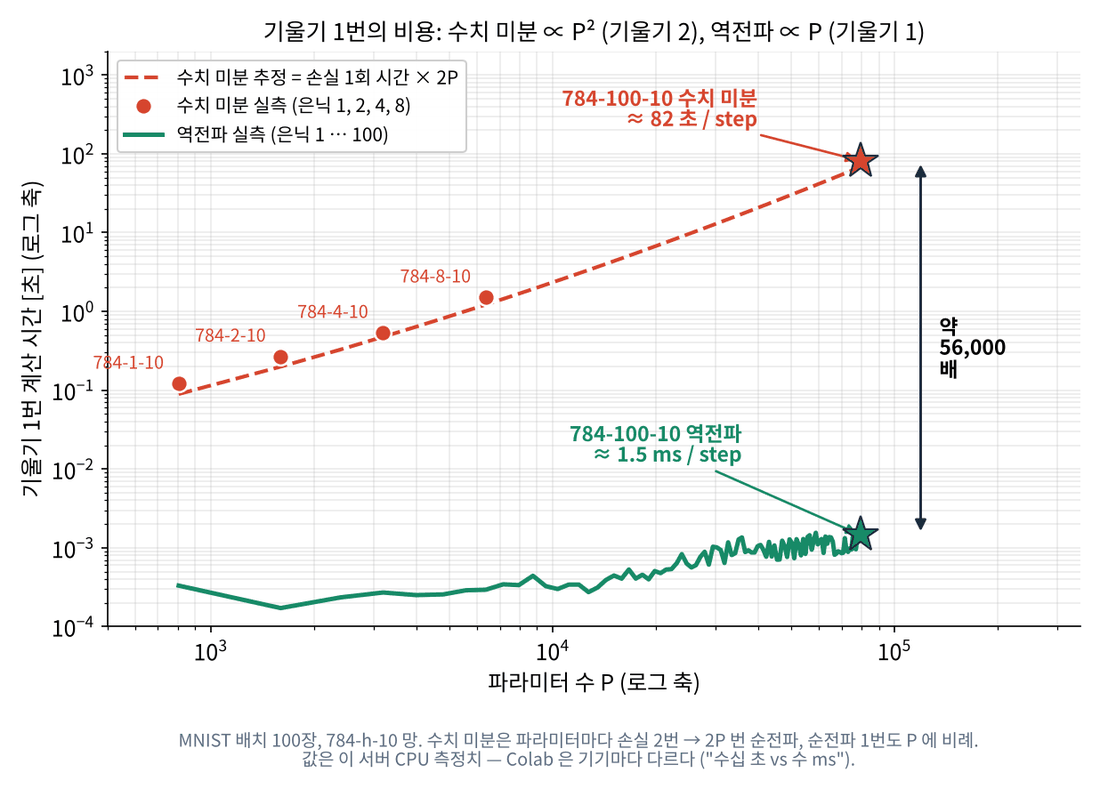

그래프의 두 선은 기울기가 다릅니다. 수치 미분(위)은 $P^2$, 역전파(아래)는 $P$ 에 비례합니다. 784-100-10 에서 **수치 미분은 step 당 수십~100 초, 역전파는 수 ms** — 수만 배 차이입니다 (정확한 숫자는 CPU 마다 다름, 위에서 직접 잰 값을 보세요). 컴퓨터가 빨라져도 이 **차수(order)** 의 차이는 줄지 않습니다.

> 그래도 수치 미분은 버리지 않습니다. 느리지만 **구현이 단순해서 틀리기 어렵기 때문에**, 6교시에서 역전파 구현이 맞는지 확인하는 "정답지"(gradient check)로 씁니다.

#### 📌 1교시 정리

- 수치 미분: step 당 순전파 $2P$ 번 → 비용 $O(P^2)$. 784-100-10 은 step 당 손실 159,020번.
- 역전파: 순전파 1번 + 역방향 1번 → 비용 $O(P)$.
- 수치 미분은 학습이 아니라 **검증**용.

## 2교시 — 계산 그래프

**계산 그래프(computational graph)** 는 계산 과정을 **노드(연산)** 와 **엣지(값)** 로 그린 그림입니다. 복잡한 식도 "작은 계산의 연결"로 쪼개면, 기울기도 작은 조각마다 구해서 이어 붙일 수 있습니다.

> 🎬 **애니메이션** [D3-2 계산 그래프 — 사과 · 귤 쇼핑](https://imguru-mooc.github.io/AI_CAMPUS/NN-day3/animation.html#d3-2)  
> 📝 **워크시트** [2교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day3/worksheet.html#t2)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

### 예제 — 사과 · 귤 쇼핑

사과 1개 100원짜리를 2개, 귤 1개 150원짜리를 3개 사고, 소비세 10% 를 붙입니다.

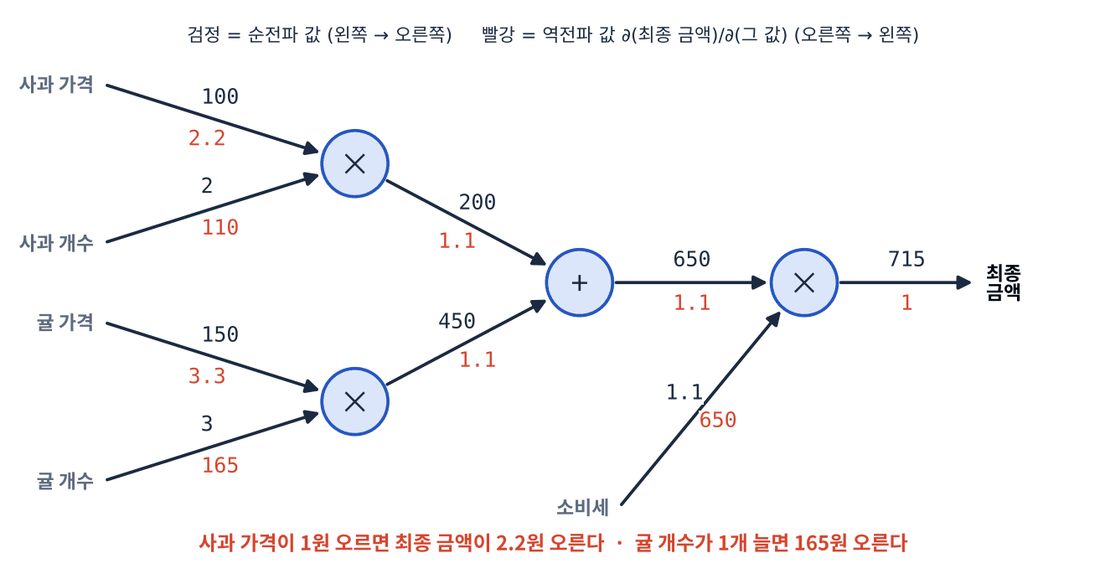

| 방향 | 무엇이 흐르나 | 계산 순서 |
|---|---|---|
| **순전파** (왼쪽 → 오른쪽) | 값 | 사과 합 200, 귤 합 450, 합계 650, 최종 715 |
| **역전파** (오른쪽 → 왼쪽) | **기울기** $\partial(\text{최종 금액}) / \partial(\cdot)$ | 출력에서 1 로 시작해 노드마다 국소 미분을 곱하며 거꾸로 |

역전파로 얻는 값의 의미: **"그 값이 1 오르면 최종 금액이 얼마나 오르나"**. 예를 들어 사과 가격의 기울기가 2.2 라면, 사과 가격이 1원 오를 때 최종 금액은 2.2원 오릅니다 (2개 × 세금 1.1).

**문제 2-1** 그래프를 따라 순전파 값을 계산하세요.

In [ ]:
apple, apple_num = 100, 2
orange, orange_num = 150, 3
tax = 1.1

apple_price = ____          # 곱셈 노드
orange_price = ____       # 곱셈 노드
all_price = ____   # 덧셈 노드
price = ____                  # 곱셈 노드

In [ ]:
assert (apple_price, orange_price, all_price) == (200, 450, 650) and np.isclose(price, 715)
print("✅ 최종 금액", round(price, 2))

In [ ]:
#@title 🔒 정답 보기 2-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTEg4pSA4pSACmFwcGxlLCBhcHBsZV9udW0gPSAxMDAsIDIKb3JhbmdlLCBvcmFuZ2Vf"
    "bnVtID0gMTUwLCAzCnRheCA9IDEuMQoKYXBwbGVfcHJpY2UgPSBhcHBsZSAqIGFwcGxlX251bSAgICAgICAgICAj"
    "IOqzseyFiCDrhbjrk5wKb3JhbmdlX3ByaWNlID0gb3JhbmdlICogb3JhbmdlX251bSAgICAgICAjIOqzseyFiCDr"
    "hbjrk5wKYWxsX3ByaWNlID0gYXBwbGVfcHJpY2UgKyBvcmFuZ2VfcHJpY2UgICAjIOuNp+yFiCDrhbjrk5wKcHJp"
    "Y2UgPSBhbGxfcHJpY2UgKiB0YXggICAgICAgICAgICAgICAgICAjIOqzseyFiCDrhbjrk5w="
).decode("utf-8"))

**문제 2-2** 이번에는 **오른쪽에서 왼쪽으로** 기울기를 손으로 계산합니다. 규칙은 두 개뿐입니다 (3교시에서 이유를 봅니다).

- **곱셈 노드** $z = x \cdot y$: $x$ 쪽으로는 (위에서 온 기울기) × $y$, $y$ 쪽으로는 (위에서 온 기울기) × $x$ — **상대편 값을 곱한다**.
- **덧셈 노드** $z = x + y$: 위에서 온 기울기를 **그대로** 양쪽에 보낸다.

In [ ]:
dprice = 1                                   # 출발: ∂price/∂price = 1

dall_price = ____                  # 곱셈 노드 (all_price × tax)
dtax = ____

dapple_price = ____              # 덧셈 노드 — 그대로
dorange_price = ____

dapple = ____          # 곱셈 노드 (apple × apple_num)
dapple_num = ____
dorange = ____
dorange_num = ____

In [ ]:
mine = [dapple, dapple_num, dorange, dorange_num, dtax]
print("사과 가격 · 사과 개수 · 귤 가격 · 귤 개수 · 소비세 =", np.round(mine, 4))
assert np.allclose(mine, [2.2, 110, 3.3, 165, 650]); print("✅")

In [ ]:
#@title 🔒 정답 보기 2-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTIg4pSA4pSACmRwcmljZSA9IDEgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAg"
    "ICAgICMg7Lac67CcOiDiiIJwcmljZS/iiIJwcmljZSA9IDEKCmRhbGxfcHJpY2UgPSBkcHJpY2UgKiB0YXggICAg"
    "ICAgICAgICAgICAgICAjIOqzseyFiCDrhbjrk5wgKGFsbF9wcmljZSDDlyB0YXgpCmR0YXggPSBkcHJpY2UgKiBh"
    "bGxfcHJpY2UKCmRhcHBsZV9wcmljZSA9IGRhbGxfcHJpY2UgKiAxICAgICAgICAgICAgICAjIOuNp+yFiCDrhbjr"
    "k5wg4oCUIOq3uOuMgOuhnApkb3JhbmdlX3ByaWNlID0gZGFsbF9wcmljZSAqIDEKCmRhcHBsZSA9IGRhcHBsZV9w"
    "cmljZSAqIGFwcGxlX251bSAgICAgICAgICAjIOqzseyFiCDrhbjrk5wgKGFwcGxlIMOXIGFwcGxlX251bSkKZGFw"
    "cGxlX251bSA9IGRhcHBsZV9wcmljZSAqIGFwcGxlCmRvcmFuZ2UgPSBkb3JhbmdlX3ByaWNlICogb3JhbmdlX251"
    "bQpkb3JhbmdlX251bSA9IGRvcmFuZ2VfcHJpY2UgKiBvcmFuZ2U="
).decode("utf-8"))

**문제 2-3** 손으로 구한 기울기가 맞는지 Day 1 의 `numerical_gradient` 로 확인하세요. 입력 다섯 개를 배열 `v` 하나로 묶습니다.

In [ ]:
def total(v):
    a, an, o, on, tx = v
    return (a * an + o * on) * tx

v = np.array([100.0, 2.0, 150.0, 3.0, 1.1])
num = ____

In [ ]:
print("수치 미분:", num)
assert np.allclose(num, mine, atol=1e-4); print("✅ 손 역전파 = 수치 미분")

In [ ]:
#@title 🔒 정답 보기 2-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTMg4pSA4pSACmRlZiB0b3RhbCh2KToKICAgIGEsIGFuLCBvLCBvbiwgdHggPSB2CiAg"
    "ICByZXR1cm4gKGEgKiBhbiArIG8gKiBvbikgKiB0eAoKdiA9IG5wLmFycmF5KFsxMDAuMCwgMi4wLCAxNTAuMCwg"
    "My4wLCAxLjFdKQpudW0gPSBudW1lcmljYWxfZ3JhZGllbnQodG90YWwsIHYp"
).decode("utf-8"))

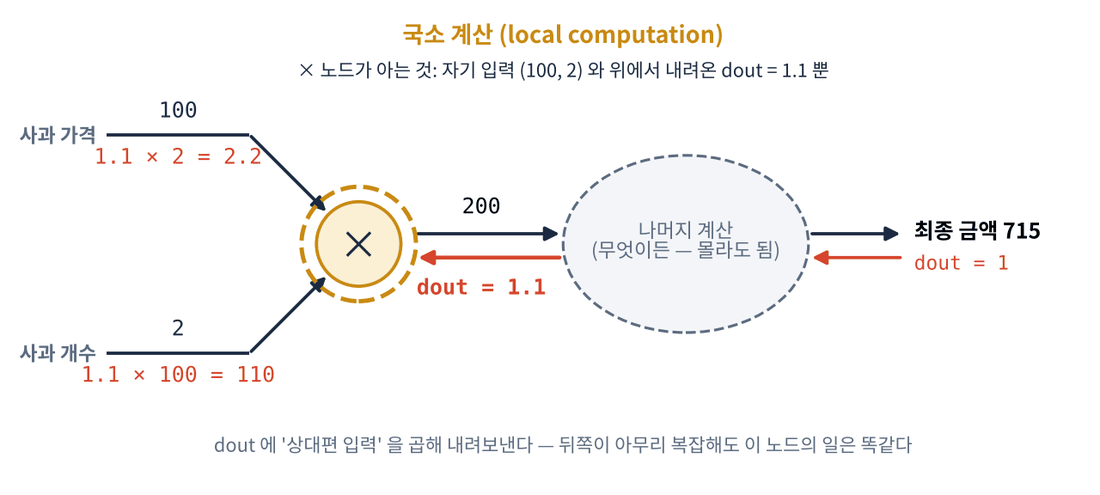

### 계산 그래프의 핵심 — 국소 계산

곱셈 노드 `× tax` 는 최종 금액이 어떻게 쓰이는지, 앞에서 사과가 몇 개였는지 **몰라도** 됩니다. 자기 입력(650, 1.1)과 위에서 내려온 기울기만으로 자기 몫을 계산해 아래로 넘깁니다. 이것을 **국소 계산(local computation)** 이라고 합니다.

- 신경망이 아무리 커도 노드 하나가 하는 일은 단순하다 → 노드 종류마다 forward · backward 를 **한 번만** 구현하면 된다.
- 중간 결과(사과 합, 귤 합 …)를 순전파 때 **저장**해 두면 역전파 때 다시 계산하지 않는다.
- 역전파 한 번으로 **모든** 입력의 기울기가 동시에 나온다 — 수치 미분은 입력마다 따로 계산해야 했다.

#### 📌 2교시 정리

- 계산 그래프 = 노드(연산) + 엣지(값). 순전파는 값을, 역전파는 기울기를 나른다.
- 역전파 값 = "그 값이 1 오르면 출력이 얼마나 오르나".
- 노드는 국소 계산만 한다 → 노드별 forward/backward 를 만들어 조립하면 된다.

## 3교시 — 연쇄 법칙

2교시의 "상대편 값을 곱한다", "그대로 보낸다" 규칙은 어디서 왔을까요? **연쇄 법칙(chain rule)** — 합성 함수의 미분은 각 단계 미분의 **곱** — 에서 나옵니다.

> 🎬 **애니메이션** [D3-3 연쇄 법칙 · 덧셈/곱셈 노드](https://imguru-mooc.github.io/AI_CAMPUS/NN-day3/animation.html#d3-3)  
> 📝 **워크시트** [3교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day3/worksheet.html#t3)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

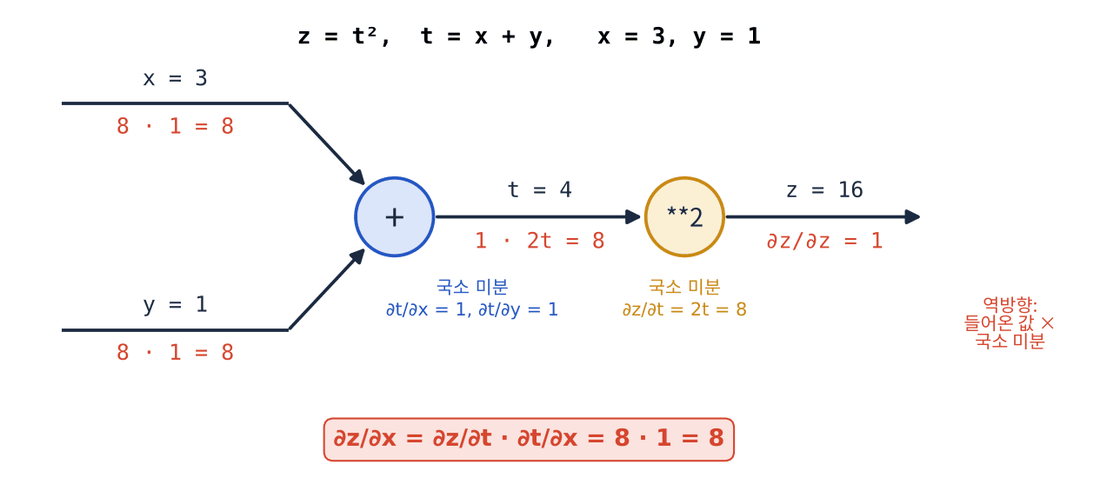

$z = (x + y)^2$ 을 두 단계로 나눕니다: $t = x + y$, $z = t^2$.

$$\frac{\partial z}{\partial x} = \frac{\partial z}{\partial t} \cdot \frac{\partial t}{\partial x} = 2t \cdot 1$$

$x = 3,\ y = 1$ 이면 $t = 4,\ z = 16$ 이고 $\partial z/\partial x = 8 \cdot 1 = 8$, $\partial z/\partial y = 8$.

역전파는 연쇄 법칙을 그래프 위에서 실행하는 것입니다. 출력 쪽에서 1 을 출발시켜, 노드를 하나 지날 때마다 그 노드의 **국소 미분**을 곱합니다.

In [ ]:
x, y = 3.0, 1.0
t_ = x + y;  z = t_ ** 2
dz = 1.0
dt = dz * 2 * t_            # z = t² 노드: 국소 미분 2t
dx, dy = dt * 1, dt * 1     # t = x + y 노드: 국소 미분 1, 1
num = numerical_gradient(lambda v: (v[0] + v[1]) ** 2, np.array([3.0, 1.0]))
print(f"z = {z},  역전파 dz/dx = {dx}, dz/dy = {dy}  |  수치 미분 {num}")

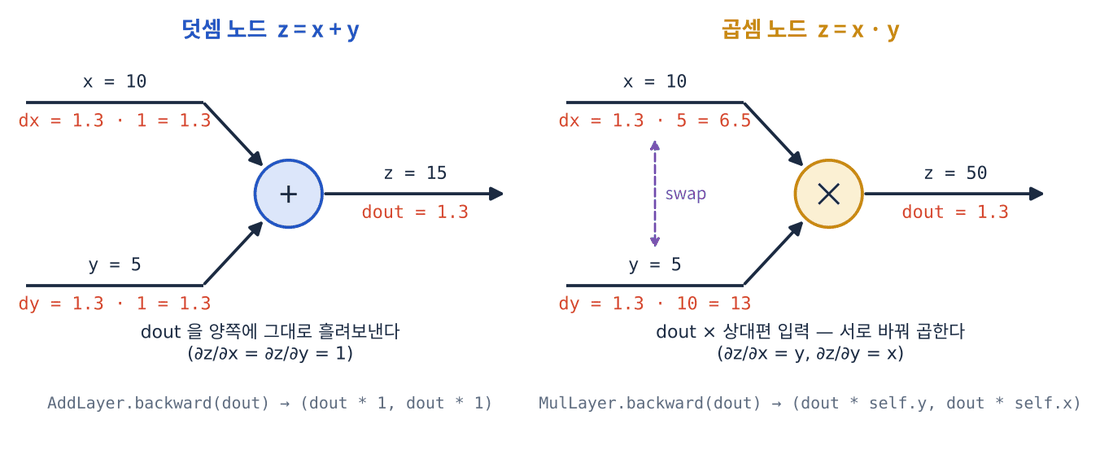

### 두 가지 기본 노드

| 노드 | 순전파 | 국소 미분 | 역전파 (위에서 온 기울기 = `dout`) |
|---|---|---|---|
| 덧셈 $z = x + y$ | $x + y$ | $\partial z/\partial x = 1,\ \partial z/\partial y = 1$ | `dx = dout * 1`, `dy = dout * 1` — **그대로 복사** |
| 곱셈 $z = x \cdot y$ | $x \cdot y$ | $\partial z/\partial x = y,\ \partial z/\partial y = x$ | `dx = dout * y`, `dy = dout * x` — **서로 바꿔 곱함** |

곱셈 노드는 역전파 때 **순전파 입력 $x, y$ 가 필요**합니다. 그래서 계층 클래스는 `forward` 에서 입력을 `self.x`, `self.y` 에 **저장**해 둡니다. 이 "forward 에서 저장 → backward 에서 사용" 패턴이 오늘 만드는 모든 계층의 공통 구조입니다.

**문제 3-1** 곱셈 계층 `MulLayer` 를 완성하세요.

In [ ]:
class MulLayer:
    def __init__(self):
        self.x = None
        self.y = None

    def forward(self, x, y):
        self.x = x                     # 역전파에 쓰려고 저장
        self.y = y
        return ____

    def backward(self, dout):
        dx = ____           # 상대편 입력을 곱한다
        dy = ____
        return dx, dy

In [ ]:
mul_apple, mul_tax = MulLayer(), MulLayer()
p = mul_tax.forward(mul_apple.forward(100, 2), 1.1)        # 사과만: (100 × 2) × 1.1
dap, dtx = mul_tax.backward(1)
da, dn = mul_apple.backward(dap)
print("가격", round(p, 2), "| d사과가격", round(da, 2), " d개수", round(dn, 2), " d소비세", round(dtx, 2))
assert np.isclose(p, 220) and np.allclose([da, dn, dtx], [2.2, 110, 200]); print("✅")

In [ ]:
#@title 🔒 정답 보기 3-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTEg4pSA4pSACmNsYXNzIE11bExheWVyOgogICAgZGVmIF9faW5pdF9fKHNlbGYpOgog"
    "ICAgICAgIHNlbGYueCA9IE5vbmUKICAgICAgICBzZWxmLnkgPSBOb25lCgogICAgZGVmIGZvcndhcmQoc2VsZiwg"
    "eCwgeSk6CiAgICAgICAgc2VsZi54ID0geCAgICAgICAgICAgICAgICAgICAgICMg7Jet7KCE7YyM7JeQIOyTsOug"
    "pOqzoCDsoIDsnqUKICAgICAgICBzZWxmLnkgPSB5CiAgICAgICAgcmV0dXJuIHggKiB5CgogICAgZGVmIGJhY2t3"
    "YXJkKHNlbGYsIGRvdXQpOgogICAgICAgIGR4ID0gZG91dCAqIHNlbGYueSAgICAgICAgICAgIyDsg4HrjIDtjrgg"
    "7J6F66Cl7J2EIOqzse2VnOuLpAogICAgICAgIGR5ID0gZG91dCAqIHNlbGYueAogICAgICAgIHJldHVybiBkeCwg"
    "ZHk="
).decode("utf-8"))

**문제 3-2** 덧셈 계층 `AddLayer` 를 완성하세요. 덧셈의 역전파는 입력 값이 필요 없으므로 아무것도 저장하지 않습니다.

In [ ]:
class AddLayer:
    def forward(self, x, y):
        return ____

    def backward(self, dout):
        dx = ____
        dy = ____
        return dx, dy

In [ ]:
#@title 🔒 정답 보기 3-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTIg4pSA4pSACmNsYXNzIEFkZExheWVyOgogICAgZGVmIGZvcndhcmQoc2VsZiwgeCwg"
    "eSk6CiAgICAgICAgcmV0dXJuIHggKyB5CgogICAgZGVmIGJhY2t3YXJkKHNlbGYsIGRvdXQpOgogICAgICAgIGR4"
    "ID0gZG91dCAqIDEKICAgICAgICBkeSA9IGRvdXQgKiAxCiAgICAgICAgcmV0dXJuIGR4LCBkeQ=="
).decode("utf-8"))

**문제 3-3** 계층 네 개로 사과 · 귤 그래프를 조립하세요. **역전파는 순전파의 반대 순서**로 호출합니다.

In [ ]:
mul_apple, mul_orange, add_all, mul_tax = MulLayer(), MulLayer(), AddLayer(), MulLayer()

# 순전파: 왼쪽 → 오른쪽
apple_price = mul_apple.forward(100, 2)
orange_price = mul_orange.forward(150, 3)
all_price = ____
price = mul_tax.forward(all_price, 1.1)

# 역전파: 오른쪽 → 왼쪽 (호출 순서가 정확히 반대)
dall_price, dtax = mul_tax.backward(1)
dapple_price, dorange_price = ____
dorange, dorange_num = ____
dapple, dapple_num = ____

In [ ]:
res = [dapple, dapple_num, dorange, dorange_num, dtax]
print("최종", round(price, 2), "| 기울기", np.round(res, 4))
assert np.isclose(price, 715) and np.allclose(res, [2.2, 110, 3.3, 165, 650]); print("✅ 2교시 손 계산과 같습니다")

In [ ]:
#@title 🔒 정답 보기 3-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTMg4pSA4pSACm11bF9hcHBsZSwgbXVsX29yYW5nZSwgYWRkX2FsbCwgbXVsX3RheCA9"
    "IE11bExheWVyKCksIE11bExheWVyKCksIEFkZExheWVyKCksIE11bExheWVyKCkKCiMg7Iic7KCE7YyMOiDsmbzs"
    "qr0g4oaSIOyYpOuluOyqvQphcHBsZV9wcmljZSA9IG11bF9hcHBsZS5mb3J3YXJkKDEwMCwgMikKb3JhbmdlX3By"
    "aWNlID0gbXVsX29yYW5nZS5mb3J3YXJkKDE1MCwgMykKYWxsX3ByaWNlID0gYWRkX2FsbC5mb3J3YXJkKGFwcGxl"
    "X3ByaWNlLCBvcmFuZ2VfcHJpY2UpCnByaWNlID0gbXVsX3RheC5mb3J3YXJkKGFsbF9wcmljZSwgMS4xKQoKIyDs"
    "l63soITtjIw6IOyYpOuluOyqvSDihpIg7Jm87Kq9ICjtmLjstpwg7Iic7ISc6rCAIOygle2Zle2eiCDrsJjrjIAp"
    "CmRhbGxfcHJpY2UsIGR0YXggPSBtdWxfdGF4LmJhY2t3YXJkKDEpCmRhcHBsZV9wcmljZSwgZG9yYW5nZV9wcmlj"
    "ZSA9IGFkZF9hbGwuYmFja3dhcmQoZGFsbF9wcmljZSkKZG9yYW5nZSwgZG9yYW5nZV9udW0gPSBtdWxfb3Jhbmdl"
    "LmJhY2t3YXJkKGRvcmFuZ2VfcHJpY2UpCmRhcHBsZSwgZGFwcGxlX251bSA9IG11bF9hcHBsZS5iYWNrd2FyZChk"
    "YXBwbGVfcHJpY2UpCgrwn5KhIO2VtOyEpArqs4TsuLXrp4jri6QgZm9yd2FyZCDsmYAgYmFja3dhcmQg66W8IO2V"
    "nCDsjI3snLzroZwg66eM65Ok7Ja0IOuRkOuptCwg6re4656Y7ZSEIOyhsOumveydgCBmb3J3YXJkIOulvCDssKjr"
    "oYDroZwsIGJhY2t3YXJkIOulvCDrsJjrjIAg7Iic7ISc66GcIOu2gOultOuKlCDqsoPrv5DsnoXri4jri6QuIOyL"
    "oOqyveunneuPhCDrmJHqsJnsirXri4jri6Qg4oCUIDbqtZDsi5wgVHdvTGF5ZXJOZXQg7J2AIOqzhOy4teydhCBP"
    "cmRlcmVkRGljdCDsl5Ag64Sj6rOgIGZvcndhcmQg64qUIOyInOyEnOuMgOuhnCwgYmFja3dhcmQg64qUIHJldmVy"
    "c2VkIOuhnCDrtoDrpoXri4jri6Qu"
).decode("utf-8"))

#### ⚠️ 자주 하는 실수

- `MulLayer.backward` 에서 `dx = dout * self.x` — 자기 자신을 곱하면 틀립니다. 곱셈 노드는 **상대편**을 곱합니다.
- 같은 `MulLayer` 객체를 두 곳에 재사용 — forward 를 두 번 부르면 저장된 `self.x`, `self.y` 가 덮어써져 첫 번째 노드의 역전파가 틀어집니다. 노드마다 **객체 하나씩**.
- 역전파 호출 순서를 순전파와 같은 순서로 — 아직 계산되지 않은 `dout` 을 쓰게 됩니다.

#### 📌 3교시 정리

- 연쇄 법칙: 합성 함수의 미분 = 단계별 국소 미분의 곱 → 역전파는 출력에서 1 을 출발시켜 국소 미분을 곱해 나간다.
- 덧셈 노드: 그대로 복사. 곱셈 노드: 서로 바꿔 곱함.
- 계층 = `forward` (값 계산 + 필요한 값 저장) + `backward` (dout 받아 입력 쪽 기울기 반환).

## 4교시 — 활성화 계층: ReLU · Sigmoid

Day 2 의 활성화 함수를 **계층**으로 만듭니다. 이제 배열 전체를 한꺼번에 다룹니다 — 모든 원소가 각자 독립된 노드라고 생각하면 됩니다.

> 🎬 **애니메이션** [D3-4 ReLU · Sigmoid 계층](https://imguru-mooc.github.io/AI_CAMPUS/NN-day3/animation.html#d3-4)  
> 📝 **워크시트** [4교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day3/worksheet.html#t4)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

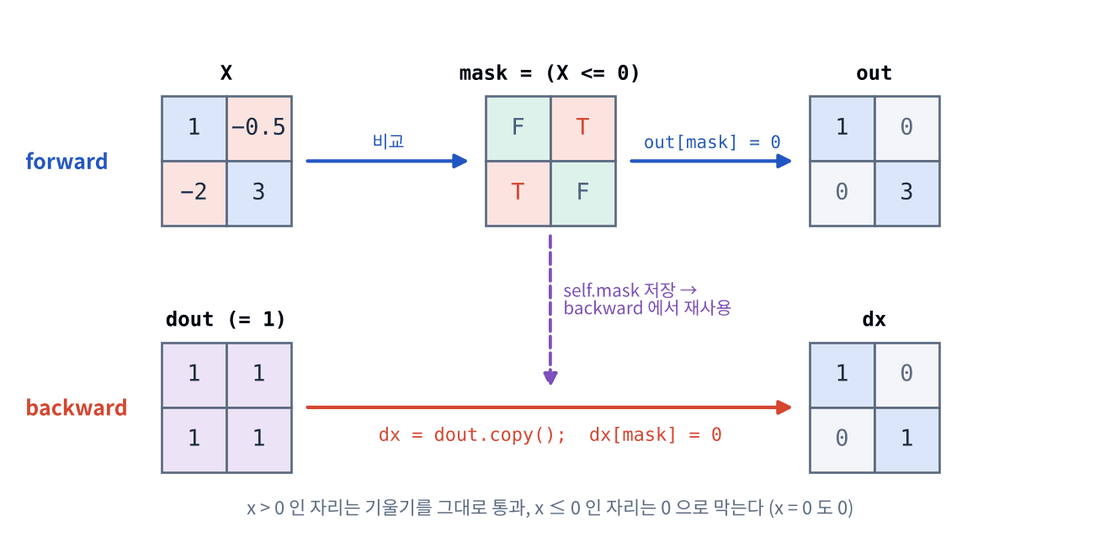

### ReLU

$$y = \begin{cases} x & (x > 0) \\ 0 & (x \le 0) \end{cases} \qquad \frac{\partial y}{\partial x} = \begin{cases} 1 & (x > 0) \\ 0 & (x \le 0) \end{cases}$$

순전파 때 0 이하였던 자리는 역전파 때 기울기를 **막고**(0), 양수였던 자리는 **그대로 통과**시킵니다. 어느 자리가 막혔는지 기억하려고 forward 에서 `mask = (x <= 0)` (True/False 배열)를 저장합니다. 전기 회로의 **스위치**와 같습니다.

**문제 4-1** `Relu` 계층을 완성하세요. 불리언 배열로 인덱싱하면 True 인 자리만 고를 수 있습니다 (Day 1 의 마스크 인덱싱).

In [ ]:
class Relu:
    def __init__(self):
        self.mask = None

    def forward(self, x):
        self.mask = ____        # 0 이하인 자리 기억
        out = x.copy()
        out[self.mask] = 0
        return out

    def backward(self, dout):
        dx = dout.copy()
        dx[____] = 0            # 순전파 때 막힌 자리는 기울기도 0
        return dx

In [ ]:
r = Relu()
Xr = np.array([[1.0, -0.5], [-2.0, 3.0]])
out = r.forward(Xr)
print("out =\n", out, "\nmask =\n", r.mask, "\nbackward(1) =\n", r.backward(np.ones_like(Xr)))
assert np.array_equal(out, [[1, 0], [0, 3]]) and np.array_equal(r.backward(np.ones_like(Xr)), [[1, 0], [0, 1]])
assert np.array_equal(Xr, [[1.0, -0.5], [-2.0, 3.0]]); print("✅ (입력 배열은 바뀌지 않았습니다)")

In [ ]:
#@title 🔒 정답 보기 4-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTEg4pSA4pSACmNsYXNzIFJlbHU6CiAgICBkZWYgX19pbml0X18oc2VsZik6CiAgICAg"
    "ICAgc2VsZi5tYXNrID0gTm9uZQoKICAgIGRlZiBmb3J3YXJkKHNlbGYsIHgpOgogICAgICAgIHNlbGYubWFzayA9"
    "ICh4IDw9IDApICAgICAgICAjIDAg7J207ZWY7J24IOyekOumrCDquLDslrUKICAgICAgICBvdXQgPSB4LmNvcHko"
    "KQogICAgICAgIG91dFtzZWxmLm1hc2tdID0gMAogICAgICAgIHJldHVybiBvdXQKCiAgICBkZWYgYmFja3dhcmQo"
    "c2VsZiwgZG91dCk6CiAgICAgICAgZHggPSBkb3V0LmNvcHkoKQogICAgICAgIGR4W3NlbGYubWFza10gPSAwICAg"
    "ICAgICAgICAgIyDsiJzsoITtjIwg65WMIOunie2ejCDsnpDrpqzripQg6riw7Jq46riw64+EIDAKICAgICAgICBy"
    "ZXR1cm4gZHg="
).decode("utf-8"))

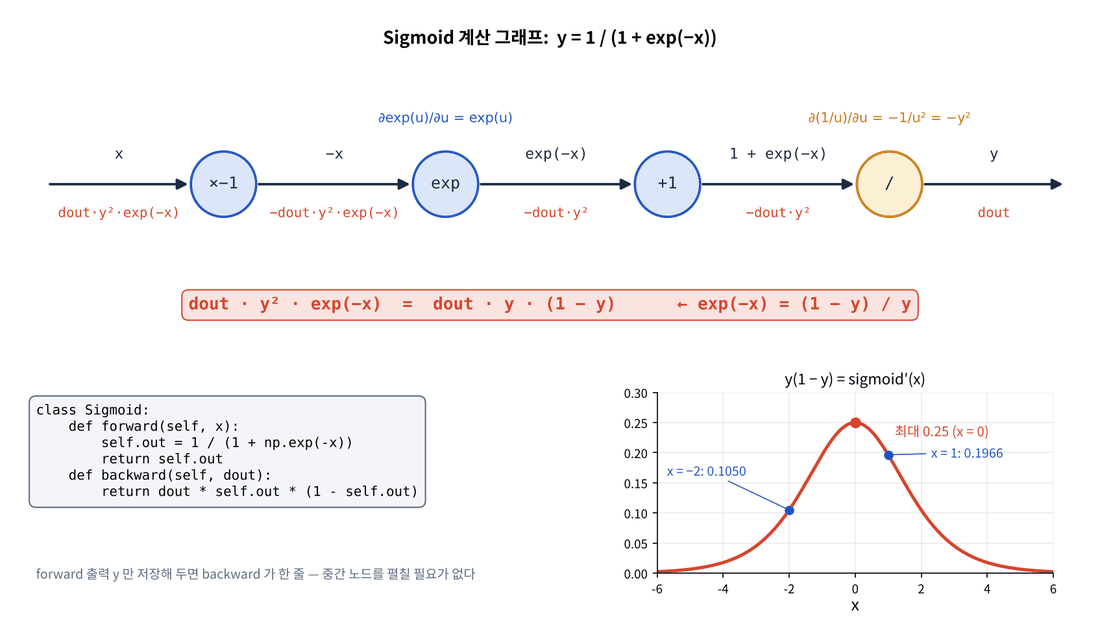

### Sigmoid

$y = \frac{1}{1 + e^{-x}}$ 를 계산 그래프로 쪼개면 `× (−1)` → `exp` → `+ 1` → `1/x` 네 노드입니다. 각 노드의 국소 미분을 곱해 정리하면

$$\frac{\partial L}{\partial x} = \text{dout} \cdot y^2 e^{-x} = \text{dout} \cdot y\,(1 - y)$$

Day 2 4교시의 `sigmoid_grad` 와 같은 식입니다. 역전파에 필요한 것은 **순전파 출력 $y$ 하나뿐**이므로 forward 에서 `self.out` 을 저장합니다 (exp 를 다시 계산하지 않음).

**문제 4-2** `Sigmoid` 계층을 완성하세요.

In [ ]:
class Sigmoid:
    def __init__(self):
        self.out = None

    def forward(self, x):
        out = ____
        self.out = out                 # 역전파에 쓰려고 저장
        return out

    def backward(self, dout):
        return ____

In [ ]:
s = Sigmoid()
y_ = s.forward(np.array([1.0, -2.0]))
print("y =", y_, " backward(1) =", s.backward(np.ones(2)))
assert np.allclose(y_, [0.7311, 0.1192], atol=1e-4) and np.allclose(s.backward(np.ones(2)), [0.1966, 0.1050], atol=1e-4)
s.forward(np.array([0.0])); assert np.isclose(s.backward(np.ones(1))[0], 0.25); print("✅ sigmoid'(0) = 0.25")

In [ ]:
#@title 🔒 정답 보기 4-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTIg4pSA4pSACmNsYXNzIFNpZ21vaWQ6CiAgICBkZWYgX19pbml0X18oc2VsZik6CiAg"
    "ICAgICAgc2VsZi5vdXQgPSBOb25lCgogICAgZGVmIGZvcndhcmQoc2VsZiwgeCk6CiAgICAgICAgb3V0ID0gMSAv"
    "ICgxICsgbnAuZXhwKC14KSkKICAgICAgICBzZWxmLm91dCA9IG91dCAgICAgICAgICAgICAgICAgIyDsl63soITt"
    "jIzsl5Ag7JOw66Ck6rOgIOyggOyepQogICAgICAgIHJldHVybiBvdXQKCiAgICBkZWYgYmFja3dhcmQoc2VsZiwg"
    "ZG91dCk6CiAgICAgICAgcmV0dXJuIGRvdXQgKiBzZWxmLm91dCAqICgxLjAgLSBzZWxmLm91dCk="
).decode("utf-8"))

**문제 4-3** 계층의 backward 가 맞는지 수치 미분으로 확인합니다. 임의의 `dout` 에 대해 $L = \sum(\text{forward}(x) \odot \text{dout})$ 로 놓으면 $\partial L / \partial x = $ `backward(dout)` 여야 합니다. (다음 교시들의 확인 셀도 모두 이 방법을 씁니다)

In [ ]:
rng4 = np.random.default_rng(4)
x0 = rng4.normal(size=(3, 4))
dout = rng4.normal(size=(3, 4))
sg = Sigmoid()

f = lambda x: np.sum(sg.forward(x) * dout)
num_dx = ____
sg.forward(x0)                          # 수치 미분이 self.out 을 바꿔 놓았으므로 다시 순전파
bp_dx = ____

In [ ]:
print("최대 차이:", np.abs(num_dx - bp_dx).max())
assert np.allclose(num_dx, bp_dx, atol=1e-8); print("✅ Sigmoid.backward 가 수치 미분과 같습니다")

In [ ]:
#@title 🔒 정답 보기 4-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTMg4pSA4pSACnJuZzQgPSBucC5yYW5kb20uZGVmYXVsdF9ybmcoNCkKeDAgPSBybmc0"
    "Lm5vcm1hbChzaXplPSgzLCA0KSkKZG91dCA9IHJuZzQubm9ybWFsKHNpemU9KDMsIDQpKQpzZyA9IFNpZ21vaWQo"
    "KQoKZiA9IGxhbWJkYSB4OiBucC5zdW0oc2cuZm9yd2FyZCh4KSAqIGRvdXQpCm51bV9keCA9IG51bWVyaWNhbF9n"
    "cmFkaWVudChmLCB4MCkKc2cuZm9yd2FyZCh4MCkgICAgICAgICAgICAgICAgICAgICAgICAgICMg7IiY7LmYIOuv"
    "uOu2hOydtCBzZWxmLm91dCDsnYQg67CU6r+UIOuGk+yVmOycvOuvgOuhnCDri6Tsi5wg7Iic7KCE7YyMCmJwX2R4"
    "ID0gc2cuYmFja3dhcmQoZG91dCkKCvCfkqEg7ZW07ISkCmYg64qUIHgg66W8IOyKpOy5vOudvCDtlZjrgpjroZwg"
    "67CU6r6464qUIO2VqOyImOudvOyEnCBudW1lcmljYWxfZ3JhZGllbnQg66W8IOuwlOuhnCDsk7gg7IiYIOyeiOyK"
    "teuLiOuLpC4gZG91dCDsnYQg66y07J6R7JyE66GcIOyeoeycvOuptCAn7JyE7JeQ7IScIOyWtOuWpCDquLDsmrjq"
    "uLDqsIAg7JmA64+EJyDrp57ripTsp4Ag7ZWcIOuyiOyXkCDtmZXsnbjrkKnri4jri6QuIOyImOy5mCDrr7jrtoTs"
    "nbQgZm9yd2FyZCDrpbwg7Jes65+sIOuyiCDrtoDrpbTrqbTshJwgc2VsZi5vdXQg7J20IOuniOyngOuniSDtmLjs"
    "tpwg6rCS7Jy866GcIOuwlOuAjOuvgOuhnCwgYmFja3dhcmQg7KCE7JeQIOybkOuemCB4MCDroZwgZm9yd2FyZCDr"
    "pbwg64uk7IucIOu2iOufrOyVvCDtlanri4jri6Qg4oCUIOqzhOy4teydtCAn7KCA7J6l7ZWcIOqwkifsl5Ag7J2Y"
    "7KG07ZWc64uk64qUIOymneqxsOyeheuLiOuLpC4="
).decode("utf-8"))

#### ⚠️ 자주 하는 실수

- `Relu.forward` 에서 `x[self.mask] = 0` 처럼 **입력을 직접** 바꾸면, 바깥의 원본 배열(예: 앞 계층 출력)이 망가집니다. `x.copy()` 에 작업하세요.
- `Sigmoid.backward` 에서 `sigmoid(dout)` 같은 식을 쓰는 실수 — 역전파는 **저장한 출력** `self.out` 으로 계산합니다.
- forward 없이 backward 를 부르면 `self.mask`/`self.out` 이 `None` 이라 오류가 납니다. 항상 forward → backward 순서.

#### 📌 4교시 정리

- ReLU: forward 에서 `mask = (x <= 0)` 저장, backward 에서 mask 자리 0 — 스위치.
- Sigmoid: forward 에서 출력 `out` 저장, backward `dout * out * (1 − out)`.
- 계층의 backward 는 $L = \sum(\text{forward}(x) \odot \text{dout})$ 의 수치 미분과 비교해 확인한다.

## 5교시 — Affine · Softmax-with-Loss 계층

신경망의 나머지 두 부품입니다. **Affine** 은 Day 2 의 가설 $Y = XW + b$ 그대로이고, **Softmax-with-Loss** 는 출력층 softmax 와 cross-entropy 손실을 한 계층으로 묶은 것입니다.

> 🎬 **애니메이션** [D3-5 Affine 역전파 shape 퍼즐](https://imguru-mooc.github.io/AI_CAMPUS/NN-day3/animation.html#d3-5) · [D3-6 Softmax-with-Loss y − t](https://imguru-mooc.github.io/AI_CAMPUS/NN-day3/animation.html#d3-6)  
> 📝 **워크시트** [5교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day3/worksheet.html#t5)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

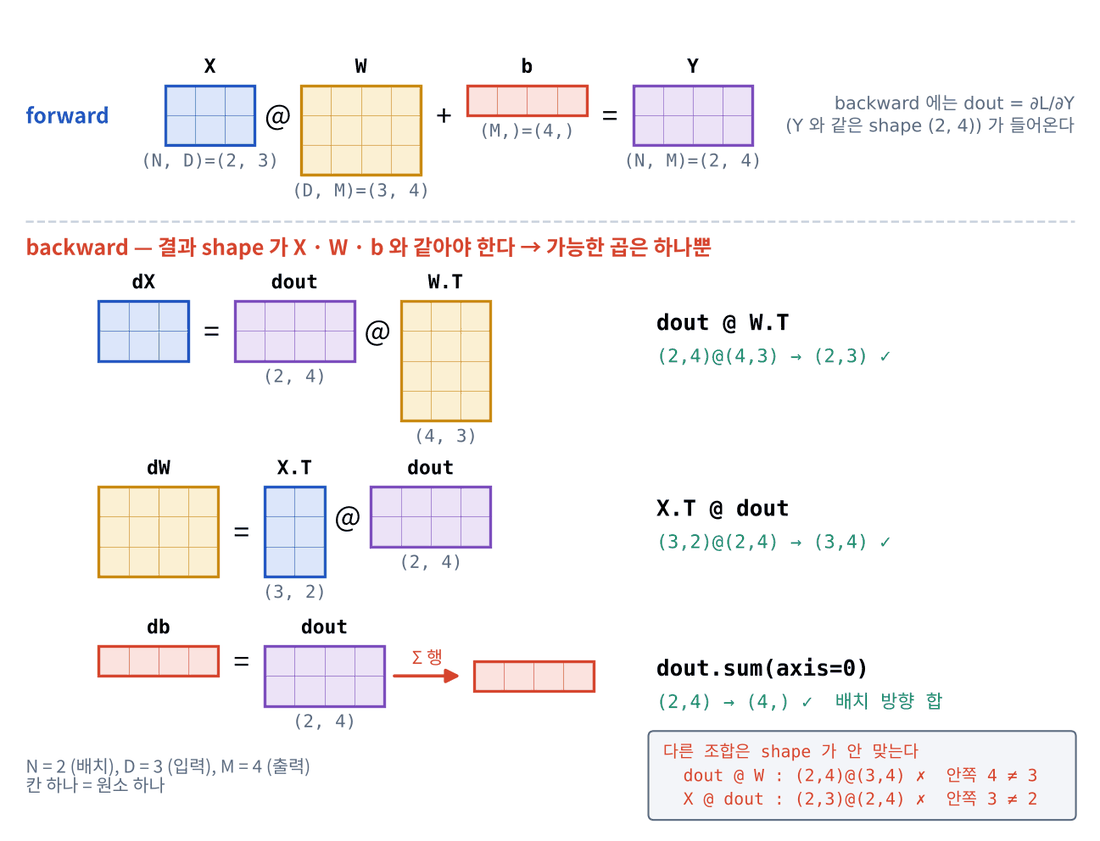

### Affine 역전파 — shape 로 유도하기

순전파 $Y = XW + b$, 위에서 내려온 기울기 $\text{dout} = \partial L / \partial Y$ 입니다.

| 기호 | shape | 기울기 | shape (자기와 같아야 함) |
|---|---|---|---|
| $X$ | (N, D) | $\partial L/\partial X$ | (N, D) |
| $W$ | (D, M) | $\partial L/\partial W$ | (D, M) |
| $b$ | (M,) | $\partial L/\partial b$ | (M,) |
| $Y$ | (N, M) | `dout` | (N, M) |

기울기는 **자기 자신과 shape 가 같습니다**. `dout` (N, M) 과 $W$ (D, M), $X$ (N, D) 로 (N, D) 를 만드는 행렬곱은 하나뿐이고, (D, M) 을 만드는 것도 하나뿐입니다.

$$\frac{\partial L}{\partial X} = \text{dout}\, W^\top \;\;(N, M)(M, D), \qquad \frac{\partial L}{\partial W} = X^\top\, \text{dout} \;\;(D, N)(N, M), \qquad \frac{\partial L}{\partial b} = \sum_{\text{행}} \text{dout}$$

- **편향은 왜 합?** 순전파에서 $b$ 는 브로드캐스팅으로 **N 개 행 모두에 더해졌습니다** (Day 1). 같은 $b$ 가 N 번 쓰였으니, 기울기는 N 개 행에서 온 것을 **모두 더합니다** (덧셈 노드의 "복사"의 반대 방향).
- **Day 2 와 같은 식** — 로지스틱 회귀의 $dW = X^\top (P - T)/N$ 은 `dout` $= (P - T)/N$ 을 넣은 $X^\top\,\text{dout}$ 이었습니다.

**문제 5-1** `Affine` 계층을 완성하세요. `W`, `b` 는 바깥(신경망의 `params`)과 **같은 배열 객체**를 가리킵니다.

In [ ]:
class Affine:
    def __init__(self, W, b):
        self.W = W
        self.b = b
        self.X = None
        self.dW = None
        self.db = None

    def forward(self, X):
        self.X = X                          # dW 계산에 필요
        return ____

    def backward(self, dout):
        dX = ____              # (N, M) @ (M, D) = (N, D)
        self.dW = ____         # (D, N) @ (N, M) = (D, M)
        self.db = ____        # (M,) — 행 방향 합
        return dX

In [ ]:
rng5 = np.random.default_rng(5)
N, D, M = 2, 3, 4
Xa, Wa, ba = rng5.normal(size=(N, D)), rng5.normal(size=(D, M)), rng5.normal(size=M)
douta = rng5.normal(size=(N, M))
aff = Affine(Wa, ba)
aff.forward(Xa); dXa = aff.backward(douta)
assert dXa.shape == (N, D) and aff.dW.shape == (D, M) and aff.db.shape == (M,)

f = lambda _: np.sum(aff.forward(Xa) * douta)          # L = Σ Y ⊙ dout
for name, mine, param in [("dX", dXa, Xa), ("dW", aff.dW, Wa), ("db", aff.db, ba)]:
    assert np.allclose(mine, numerical_gradient(f, param), atol=1e-6), name
print("✅ dX", dXa.shape, " dW", aff.dW.shape, " db", aff.db.shape, "— 모두 수치 미분과 일치")

In [ ]:
#@title 🔒 정답 보기 5-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTEg4pSA4pSACmNsYXNzIEFmZmluZToKICAgIGRlZiBfX2luaXRfXyhzZWxmLCBXLCBi"
    "KToKICAgICAgICBzZWxmLlcgPSBXCiAgICAgICAgc2VsZi5iID0gYgogICAgICAgIHNlbGYuWCA9IE5vbmUKICAg"
    "ICAgICBzZWxmLmRXID0gTm9uZQogICAgICAgIHNlbGYuZGIgPSBOb25lCgogICAgZGVmIGZvcndhcmQoc2VsZiwg"
    "WCk6CiAgICAgICAgc2VsZi5YID0gWCAgICAgICAgICAgICAgICAgICAgICAgICAgIyBkVyDqs4TsgrDsl5Ag7ZWE"
    "7JqUCiAgICAgICAgcmV0dXJuIFggQCBzZWxmLlcgKyBzZWxmLmIKCiAgICBkZWYgYmFja3dhcmQoc2VsZiwgZG91"
    "dCk6CiAgICAgICAgZFggPSBkb3V0IEAgc2VsZi5XLlQgICAgICAgICAgICAgICMgKE4sIE0pIEAgKE0sIEQpID0g"
    "KE4sIEQpCiAgICAgICAgc2VsZi5kVyA9IHNlbGYuWC5UIEAgZG91dCAgICAgICAgICMgKEQsIE4pIEAgKE4sIE0p"
    "ID0gKEQsIE0pCiAgICAgICAgc2VsZi5kYiA9IGRvdXQuc3VtKGF4aXM9MCkgICAgICAgICMgKE0sKSDigJQg7ZaJ"
    "IOuwqe2WpSDtlakKICAgICAgICByZXR1cm4gZFg="
).decode("utf-8"))

### Softmax-with-Loss — 기울기가 $Y - T$

분류 신경망의 끝은 언제나 softmax → cross-entropy 입니다. 둘을 한 계층으로 묶어 역전파하면, softmax 의 복잡한 미분과 log 의 미분이 깔끔하게 상쇄되어

$$\frac{\partial L}{\partial X} = \frac{Y - T}{N}$$

이 됩니다 ($Y$ = softmax 출력, $T$ = one-hot 정답). Day 2 에서 본 선형 회귀 · 로지스틱 회귀의 **"(예측 − 정답)"** 이 여기서 다시 나옵니다. 잘 설계된 출력층 + 손실 조합은 모두 이 모양을 갖도록 만들어져 있습니다.

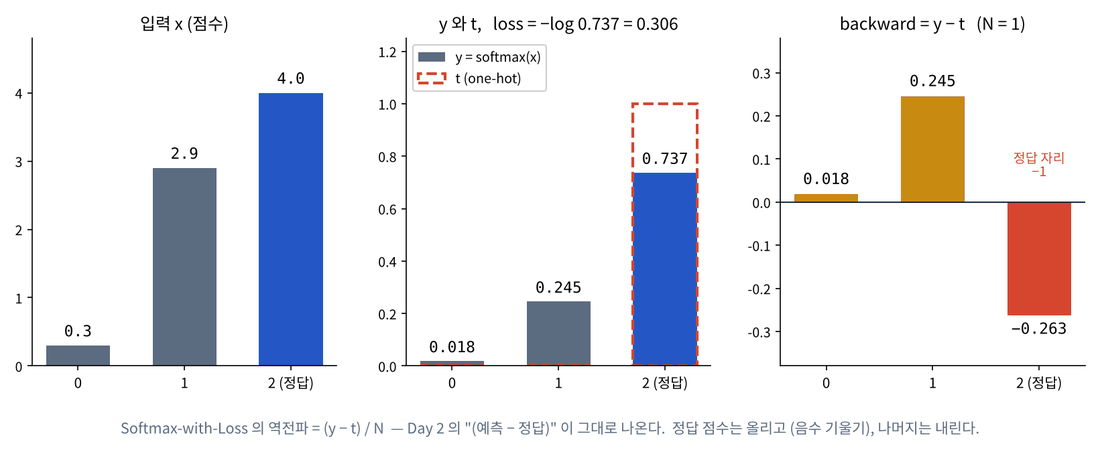

**문제 5-2** 정답이 **레이블**(정수, 예: `[2, 0]`)이어도 동작하는 cross-entropy 를 완성하세요. `y[np.arange(N), t]` 는 행마다 정답 자리의 확률 하나씩을 골라 줍니다 (팬시 인덱싱). log 에 더하는 작은 값은 이제 `1e-12` 를 씁니다 (이유는 6교시).

In [ ]:
def cross_entropy_error(y, t):
    if y.ndim == 1:                           # 샘플 하나면 배치 하나로
        y, t = y.reshape(1, -1), np.reshape(t, (1, -1))
    t = np.asarray(t)
    if t.size == y.size:                      # one-hot 이면 레이블로 바꾼다
        t = t.argmax(axis=1)
    N = y.shape[0]
    return ____

In [ ]:
yb = softmax(np.array([[0.3, 2.9, 4.0], [1.0, 2.0, 0.5]]))
assert np.isclose(cross_entropy_error(yb, np.array([2, 0])), 0.8850, atol=1e-4)
assert np.isclose(cross_entropy_error(yb, one_hot(np.array([2, 0]), 3)), 0.8850, atol=1e-4)
print("✅ 레이블 · one-hot 모두 0.8850")

In [ ]:
#@title 🔒 정답 보기 5-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTIg4pSA4pSACmRlZiBjcm9zc19lbnRyb3B5X2Vycm9yKHksIHQpOgogICAgaWYgeS5u"
    "ZGltID09IDE6ICAgICAgICAgICAgICAgICAgICAgICAgICAgIyDsg5jtlIwg7ZWY64KY66m0IOuwsOy5mCDtlZjr"
    "gpjroZwKICAgICAgICB5LCB0ID0geS5yZXNoYXBlKDEsIC0xKSwgbnAucmVzaGFwZSh0LCAoMSwgLTEpKQogICAg"
    "dCA9IG5wLmFzYXJyYXkodCkKICAgIGlmIHQuc2l6ZSA9PSB5LnNpemU6ICAgICAgICAgICAgICAgICAgICAgICMg"
    "b25lLWhvdCDsnbTrqbQg66CI7J2067iU66GcIOuwlOq+vOuLpAogICAgICAgIHQgPSB0LmFyZ21heChheGlzPTEp"
    "CiAgICBOID0geS5zaGFwZVswXQogICAgcmV0dXJuIC1ucC5zdW0obnAubG9nKHlbbnAuYXJhbmdlKE4pLCB0XSAr"
    "IDFlLTEyKSkgLyBO"
).decode("utf-8"))

**문제 5-3** `SoftmaxWithLoss` 계층을 완성하세요. 레이블일 때는 $Y$ 를 복사한 뒤 행마다 정답 자리에서 1 을 빼면 $Y - T$ 와 같습니다.

In [ ]:
class SoftmaxWithLoss:
    def __init__(self):
        self.loss = None
        self.y = None                         # softmax 출력
        self.t = None                         # 정답 (레이블 또는 one-hot)

    def forward(self, X, t):
        self.t = t
        self.y = ____
        self.loss = cross_entropy_error(self.y, self.t)
        return self.loss

    def backward(self, dout=1):
        N = self.y.shape[0]
        if self.t.size == self.y.size:        # one-hot
            dX = ____
        else:                                 # 레이블
            dX = self.y.copy()
            dX[np.arange(N), self.t] -= ____
            dX = dX / N
        return dX * dout

In [ ]:
sl = SoftmaxWithLoss()
L1 = sl.forward(np.array([[0.3, 2.9, 4.0]]), np.array([2]))
print("loss =", round(L1, 4), " y =", sl.y, " backward =", sl.backward())
assert np.isclose(L1, 0.3057, atol=1e-4) and np.allclose(sl.backward(), [[0.0182, 0.2452, -0.2634]], atol=1e-4)

Xs5, ts5 = np.array([[0.3, 2.9, 4.0], [1.0, 2.0, 0.5]]), np.array([2, 0])
sl.forward(Xs5, ts5); bp = sl.backward()
num = numerical_gradient(lambda x: SoftmaxWithLoss().forward(x, ts5), Xs5.copy())
assert np.allclose(bp, num, atol=1e-7); print("✅ 배치 2개도 수치 미분과 일치 — 정답 자리만 음수, 나머지는 양수")

In [ ]:
#@title 🔒 정답 보기 5-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTMg4pSA4pSACmNsYXNzIFNvZnRtYXhXaXRoTG9zczoKICAgIGRlZiBfX2luaXRfXyhz"
    "ZWxmKToKICAgICAgICBzZWxmLmxvc3MgPSBOb25lCiAgICAgICAgc2VsZi55ID0gTm9uZSAgICAgICAgICAgICAg"
    "ICAgICAgICAgICAjIHNvZnRtYXgg7Lac66ClCiAgICAgICAgc2VsZi50ID0gTm9uZSAgICAgICAgICAgICAgICAg"
    "ICAgICAgICAjIOygleuLtSAo66CI7J2067iUIOuYkOuKlCBvbmUtaG90KQoKICAgIGRlZiBmb3J3YXJkKHNlbGYs"
    "IFgsIHQpOgogICAgICAgIHNlbGYudCA9IHQKICAgICAgICBzZWxmLnkgPSBzb2Z0bWF4KFgpCiAgICAgICAgc2Vs"
    "Zi5sb3NzID0gY3Jvc3NfZW50cm9weV9lcnJvcihzZWxmLnksIHNlbGYudCkKICAgICAgICByZXR1cm4gc2VsZi5s"
    "b3NzCgogICAgZGVmIGJhY2t3YXJkKHNlbGYsIGRvdXQ9MSk6CiAgICAgICAgTiA9IHNlbGYueS5zaGFwZVswXQog"
    "ICAgICAgIGlmIHNlbGYudC5zaXplID09IHNlbGYueS5zaXplOiAgICAgICAgIyBvbmUtaG90CiAgICAgICAgICAg"
    "IGRYID0gKHNlbGYueSAtIHNlbGYudCkgLyBOCiAgICAgICAgZWxzZTogICAgICAgICAgICAgICAgICAgICAgICAg"
    "ICAgICAgICAjIOugiOydtOu4lAogICAgICAgICAgICBkWCA9IHNlbGYueS5jb3B5KCkKICAgICAgICAgICAgZFhb"
    "bnAuYXJhbmdlKE4pLCBzZWxmLnRdIC09IDEKICAgICAgICAgICAgZFggPSBkWCAvIE4KICAgICAgICByZXR1cm4g"
    "ZFggKiBkb3V0"
).decode("utf-8"))

**문제 5-4** 지금 만든 두 계층(Affine → SoftmaxWithLoss)은 Day 2 의 **다중 클래스 로지스틱 회귀**와 같습니다. 계층 역전파로 구한 `dW` 가 Day 2 식 $X^\top(\text{softmax}(XW + b) - T)/N$ 과 같은지 확인하세요.

In [ ]:
rng5b = np.random.default_rng(55)
X5, W5, b5 = rng5b.normal(size=(6, 4)), rng5b.normal(size=(4, 3)), rng5b.normal(size=3)
T5 = one_hot(np.array([0, 2, 1, 1, 0, 2]), 3)

aff5, sl5 = Affine(W5, b5), SoftmaxWithLoss()
sl5.forward(aff5.forward(X5), T5)
aff5.backward(sl5.backward())                      # 역전파: 손실 → Affine

day2_dW = ____

In [ ]:
print("계층 역전파 dW[0] =", aff5.dW[0], "\nDay 2 식     dW[0] =", day2_dW[0])
assert np.allclose(aff5.dW, day2_dW); print("✅ 같은 기울기 — Day 2 의 손 유도 = 계층 두 개의 역전파")

In [ ]:
#@title 🔒 정답 보기 5-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTQg4pSA4pSACnJuZzViID0gbnAucmFuZG9tLmRlZmF1bHRfcm5nKDU1KQpYNSwgVzUs"
    "IGI1ID0gcm5nNWIubm9ybWFsKHNpemU9KDYsIDQpKSwgcm5nNWIubm9ybWFsKHNpemU9KDQsIDMpKSwgcm5nNWIu"
    "bm9ybWFsKHNpemU9MykKVDUgPSBvbmVfaG90KG5wLmFycmF5KFswLCAyLCAxLCAxLCAwLCAyXSksIDMpCgphZmY1"
    "LCBzbDUgPSBBZmZpbmUoVzUsIGI1KSwgU29mdG1heFdpdGhMb3NzKCkKc2w1LmZvcndhcmQoYWZmNS5mb3J3YXJk"
    "KFg1KSwgVDUpCmFmZjUuYmFja3dhcmQoc2w1LmJhY2t3YXJkKCkpICAgICAgICAgICAgICAgICAgICAgICMg7Jet"
    "7KCE7YyMOiDshpDsi6Qg4oaSIEFmZmluZQoKZGF5Ml9kVyA9IFg1LlQgQCAoc29mdG1heChYNSBAIFc1ICsgYjUp"
    "IC0gVDUpIC8gbGVuKFg1KQ=="
).decode("utf-8"))

#### ⚠️ 자주 하는 실수

- `self.dW = dout @ self.X` 처럼 shape 만 보고 대충 바꾸기 — 정사각 행렬이면 **오류 없이** 틀린 값이 나옵니다 (6교시 버그 ②). 표의 shape 로 식을 유도하세요.
- `self.db = dout.mean(axis=0)` — 편향은 N 번 **더해졌으므로** 기울기는 합입니다. 평균으로 나누는 것은 SoftmaxWithLoss 의 `/ N` 이 이미 했습니다 (6교시 버그 ①).
- SoftmaxWithLoss 에서 `/ N` 을 빼먹으면 손실은 평균인데 기울기는 합이 되어, 배치 크기만큼 학습률이 커진 것처럼 동작합니다.
- 레이블 `t` 를 `float` 배열로 넣으면 `y[np.arange(N), t]` 인덱싱이 오류 — 레이블은 정수(`astype(int)`).

#### 📌 5교시 정리

- Affine: `dX = dout @ W.T`, `dW = X.T @ dout`, `db = dout.sum(axis=0)` — 기울기 shape = 자기 shape.
- SoftmaxWithLoss: `(Y − T) / N` — Day 2 의 "(예측 − 정답)".
- Day 2 의 손 유도 기울기 = Affine + SoftmaxWithLoss 계층의 역전파.

## 6교시 — 계층 조립과 Gradient check

부품이 다 모였습니다. 계층을 쌓아 2층 신경망 `TwoLayerNet` 을 만들고, 역전파로 구한 기울기가 정말 맞는지 **수치 미분과 비교**해 확인합니다. 이 비교를 **gradient check** 라고 합니다.

> 🎬 **애니메이션** [D3-7 Gradient check](https://imguru-mooc.github.io/AI_CAMPUS/NN-day3/animation.html#d3-7)  
> 📝 **워크시트** [6교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day3/worksheet.html#t6)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

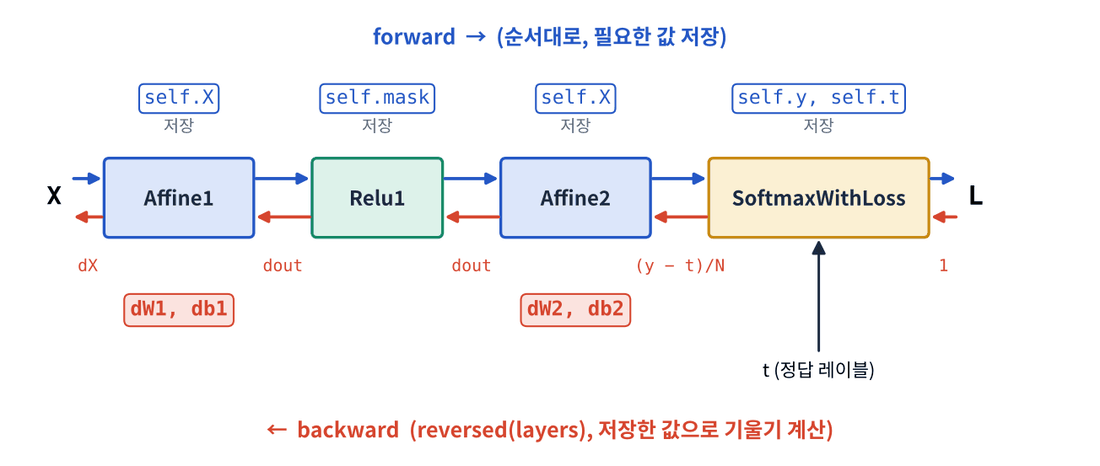

### TwoLayerNet — 계층을 OrderedDict 에 쌓는다

- `params` — 파라미터 딕셔너리 (`W1, b1, W2, b2`). Affine 계층이 **같은 배열 객체**를 가리킵니다.
- `layers` — `OrderedDict` (넣은 순서를 기억하는 딕셔너리): `Affine1 → Relu1 → Affine2`.
- `lastLayer` — `SoftmaxWithLoss`.
- `gradient()` — ① `loss()` 로 순전파 (계층마다 필요한 값 저장) → ② `lastLayer.backward(1)` → ③ `layers` 를 **reversed** 순서로 `backward` → ④ 각 Affine 의 `dW`, `db` 모으기.

**문제 6-1** `gradient` 메서드를 완성하세요.

In [ ]:
class TwoLayerNet:
    def __init__(self, input_size, hidden_size, output_size, weight_init_std=0.01, seed=0):
        rng_ = np.random.default_rng(seed)
        self.params = {
            "W1": weight_init_std * rng_.standard_normal((input_size, hidden_size)),
            "b1": np.zeros(hidden_size),
            "W2": weight_init_std * rng_.standard_normal((hidden_size, output_size)),
            "b2": np.zeros(output_size),
        }
        self.layers = OrderedDict()
        self.layers["Affine1"] = Affine(self.params["W1"], self.params["b1"])
        self.layers["Relu1"] = Relu()
        self.layers["Affine2"] = Affine(self.params["W2"], self.params["b2"])
        self.lastLayer = SoftmaxWithLoss()

    def predict(self, X):                     # 점수 (softmax 전)
        for layer in self.layers.values():
            X = layer.forward(X)
        return X

    def loss(self, X, t):
        return self.lastLayer.forward(self.predict(X), t)

    def accuracy(self, X, t):                 # t 는 레이블
        return np.mean(self.predict(X).argmax(axis=1) == t)

    def numerical_gradient(self, X, t):       # 검증용 (느림)
        f = lambda _: self.loss(X, t)
        return {k: numerical_gradient(f, self.params[k]) for k in self.params}

    def gradient(self, X, t):                 # 역전파 (빠름)
        self.loss(X, t)                       # ① 순전파 — 계층마다 값 저장
        dout = ____   # ② 손실 계층
        for layer in ____:
            dout = ____     # ③ 반대 순서로
        return {"W1": self.layers["Affine1"].dW, "b1": self.layers["Affine1"].db,
                "W2": self.layers["Affine2"].dW, "b2": self.layers["Affine2"].db}

In [ ]:
net6 = TwoLayerNet(784, 10, 10)
Xc, tc = x_train[:3].reshape(3, -1) / 255.0, y_train[:3].astype(int)       # MNIST 3장
g_bp = net6.gradient(Xc, tc)
assert {k: v.shape for k, v in g_bp.items()} == {"W1": (784, 10), "b1": (10,), "W2": (10, 10), "b2": (10,)}
print("✅ 기울기 shape:", {k: v.shape for k, v in g_bp.items()})

In [ ]:
#@title 🔒 정답 보기 6-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTEg4pSA4pSACmNsYXNzIFR3b0xheWVyTmV0OgogICAgZGVmIF9faW5pdF9fKHNlbGYs"
    "IGlucHV0X3NpemUsIGhpZGRlbl9zaXplLCBvdXRwdXRfc2l6ZSwgd2VpZ2h0X2luaXRfc3RkPTAuMDEsIHNlZWQ9"
    "MCk6CiAgICAgICAgcm5nXyA9IG5wLnJhbmRvbS5kZWZhdWx0X3JuZyhzZWVkKQogICAgICAgIHNlbGYucGFyYW1z"
    "ID0gewogICAgICAgICAgICAiVzEiOiB3ZWlnaHRfaW5pdF9zdGQgKiBybmdfLnN0YW5kYXJkX25vcm1hbCgoaW5w"
    "dXRfc2l6ZSwgaGlkZGVuX3NpemUpKSwKICAgICAgICAgICAgImIxIjogbnAuemVyb3MoaGlkZGVuX3NpemUpLAog"
    "ICAgICAgICAgICAiVzIiOiB3ZWlnaHRfaW5pdF9zdGQgKiBybmdfLnN0YW5kYXJkX25vcm1hbCgoaGlkZGVuX3Np"
    "emUsIG91dHB1dF9zaXplKSksCiAgICAgICAgICAgICJiMiI6IG5wLnplcm9zKG91dHB1dF9zaXplKSwKICAgICAg"
    "ICB9CiAgICAgICAgc2VsZi5sYXllcnMgPSBPcmRlcmVkRGljdCgpCiAgICAgICAgc2VsZi5sYXllcnNbIkFmZmlu"
    "ZTEiXSA9IEFmZmluZShzZWxmLnBhcmFtc1siVzEiXSwgc2VsZi5wYXJhbXNbImIxIl0pCiAgICAgICAgc2VsZi5s"
    "YXllcnNbIlJlbHUxIl0gPSBSZWx1KCkKICAgICAgICBzZWxmLmxheWVyc1siQWZmaW5lMiJdID0gQWZmaW5lKHNl"
    "bGYucGFyYW1zWyJXMiJdLCBzZWxmLnBhcmFtc1siYjIiXSkKICAgICAgICBzZWxmLmxhc3RMYXllciA9IFNvZnRt"
    "YXhXaXRoTG9zcygpCgogICAgZGVmIHByZWRpY3Qoc2VsZiwgWCk6ICAgICAgICAgICAgICAgICAgICAgIyDsoJDs"
    "iJggKHNvZnRtYXgg7KCEKQogICAgICAgIGZvciBsYXllciBpbiBzZWxmLmxheWVycy52YWx1ZXMoKToKICAgICAg"
    "ICAgICAgWCA9IGxheWVyLmZvcndhcmQoWCkKICAgICAgICByZXR1cm4gWAoKICAgIGRlZiBsb3NzKHNlbGYsIFgs"
    "IHQpOgogICAgICAgIHJldHVybiBzZWxmLmxhc3RMYXllci5mb3J3YXJkKHNlbGYucHJlZGljdChYKSwgdCkKCiAg"
    "ICBkZWYgYWNjdXJhY3koc2VsZiwgWCwgdCk6ICAgICAgICAgICAgICAgICAjIHQg64qUIOugiOydtOu4lAogICAg"
    "ICAgIHJldHVybiBucC5tZWFuKHNlbGYucHJlZGljdChYKS5hcmdtYXgoYXhpcz0xKSA9PSB0KQoKICAgIGRlZiBu"
    "dW1lcmljYWxfZ3JhZGllbnQoc2VsZiwgWCwgdCk6ICAgICAgICMg6rKA7Kad7JqpICjripDrprwpCiAgICAgICAg"
    "ZiA9IGxhbWJkYSBfOiBzZWxmLmxvc3MoWCwgdCkKICAgICAgICByZXR1cm4ge2s6IG51bWVyaWNhbF9ncmFkaWVu"
    "dChmLCBzZWxmLnBhcmFtc1trXSkgZm9yIGsgaW4gc2VsZi5wYXJhbXN9CgogICAgZGVmIGdyYWRpZW50KHNlbGYs"
    "IFgsIHQpOiAgICAgICAgICAgICAgICAgIyDsl63soITtjIwgKOu5oOumhCkKICAgICAgICBzZWxmLmxvc3MoWCwg"
    "dCkgICAgICAgICAgICAgICAgICAgICAgICMg4pGgIOyInOyghO2MjCDigJQg6rOE7Li166eI64ukIOqwkiDsoIDs"
    "nqUKICAgICAgICBkb3V0ID0gc2VsZi5sYXN0TGF5ZXIuYmFja3dhcmQoMSkgICAjIOKRoSDshpDsi6Qg6rOE7Li1"
    "CiAgICAgICAgZm9yIGxheWVyIGluIHJldmVyc2VkKGxpc3Qoc2VsZi5sYXllcnMudmFsdWVzKCkpKToKICAgICAg"
    "ICAgICAgZG91dCA9IGxheWVyLmJhY2t3YXJkKGRvdXQpICAgICAjIOKRoiDrsJjrjIAg7Iic7ISc66GcCiAgICAg"
    "ICAgcmV0dXJuIHsiVzEiOiBzZWxmLmxheWVyc1siQWZmaW5lMSJdLmRXLCAiYjEiOiBzZWxmLmxheWVyc1siQWZm"
    "aW5lMSJdLmRiLAogICAgICAgICAgICAgICAgIlcyIjogc2VsZi5sYXllcnNbIkFmZmluZTIiXS5kVywgImIyIjog"
    "c2VsZi5sYXllcnNbIkFmZmluZTIiXS5kYn0="
).decode("utf-8"))

### 상대 오차로 비교하기

기울기 값의 크기는 파라미터마다 다르므로 차이의 절댓값보다 **상대 오차**로 판정합니다.

$$\text{rel\_error}(a, b) = \frac{\lVert a - b \rVert}{\lVert a \rVert + \lVert b \rVert}$$

| 상대 오차 | 판정 |
|---|---|
| $< 10^{-7}$ | ✅ 통과 — 구현이 맞다 |
| $10^{-7} \sim 10^{-4}$ | ⚠️ 의심 — 꺾이는 점(ReLU 의 0) 근처이거나 손실 식이 미세하게 다름 |
| $> 10^{-2}$ | ❌ 버그 |

**문제 6-2 · 6-3** `rel_error` 를 만들고, `TwoLayerNet` 의 역전파를 수치 미분과 비교하세요. 수치 미분은 파라미터 7,960개 × 2번 순전파라 몇 초 걸립니다.

In [ ]:
def rel_error(a, b):
    return ____

g_num = ____
g_bp = net6.gradient(Xc, tc)

In [ ]:
for k in g_num:
    e = rel_error(g_bp[k], g_num[k])
    print(f"{k}: 상대 오차 {e:.2e}  {'✅' if e < 1e-7 else '❌'}")
assert all(rel_error(g_bp[k], g_num[k]) < 1e-7 for k in g_num); print("✅ gradient check 통과")

In [ ]:
#@title 🔒 정답 보기 6-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTIg4pSA4pSACmRlZiByZWxfZXJyb3IoYSwgYik6CiAgICByZXR1cm4gbnAubGluYWxn"
    "Lm5vcm0oYSAtIGIpIC8gKG5wLmxpbmFsZy5ub3JtKGEpICsgbnAubGluYWxnLm5vcm0oYikgKyAxZS0xMikKCmdf"
    "bnVtID0gbmV0Ni5udW1lcmljYWxfZ3JhZGllbnQoWGMsIHRjKQpnX2JwID0gbmV0Ni5ncmFkaWVudChYYywgdGMp"
).decode("utf-8"))

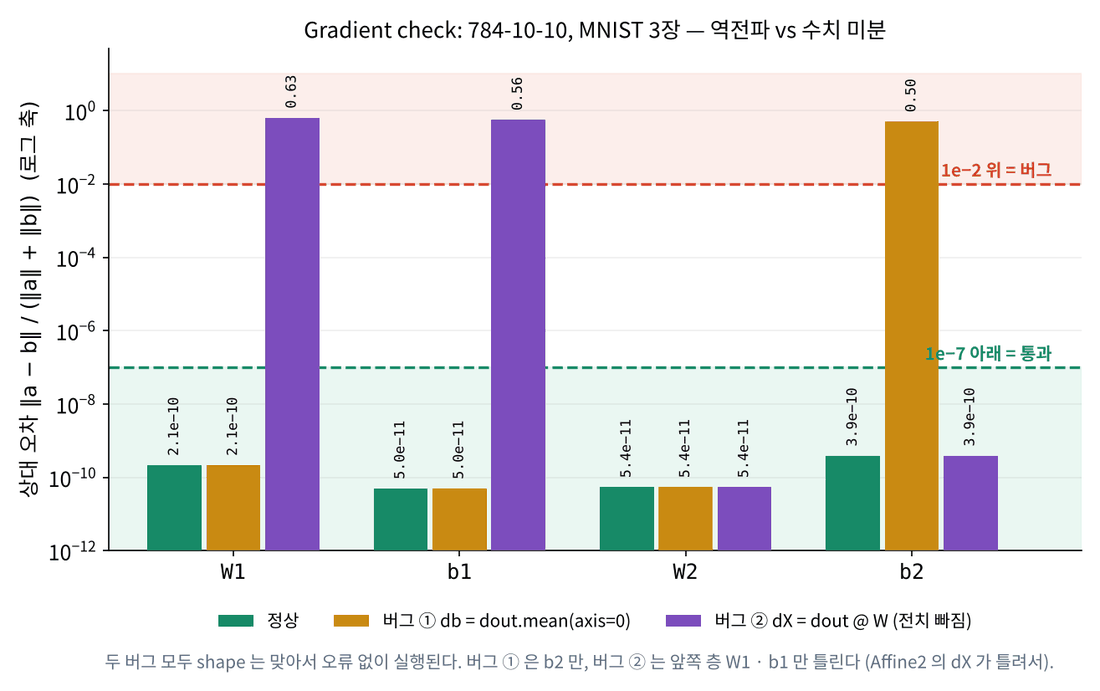

### 왜 `1e-12` 인가 — 손실 식이 다르면 기울기도 미세하게 다르다

Day 2 의 `cross_entropy` 는 log 안에 `1e-7` 을 더했습니다. 역전파 식 $Y - T$ 는 이 `1e-7` 이 **없는** 손실의 정확한 미분이므로, 수치 미분(1e-7 이 있는 손실)과 약 $5 \times 10^{-7}$ 만큼 비율 차이가 납니다. 버그는 아니지만 판정 기준을 넘습니다. 아래 셀로 확인해 보세요.

In [ ]:
class SoftmaxWithLoss_eps7(SoftmaxWithLoss):          # log 에 1e-7 을 더하는 Day 2 방식
    def forward(self, X, t):
        self.t, self.y = t, softmax(X)
        N = len(t)
        self.loss = -np.sum(np.log(self.y[np.arange(N), t] + 1e-7)) / N
        return self.loss

net_e = TwoLayerNet(784, 10, 10); net_e.lastLayer = SoftmaxWithLoss_eps7()
gn, gb = net_e.numerical_gradient(Xc, tc), net_e.gradient(Xc, tc)
print({k: f"{rel_error(gb[k], gn[k]):.1e}" for k in gn}, "← 모두 약 5e-7: 구현 버그가 아니라 손실 식의 차이")

### 버그 찾기 — shape 가 맞아도 틀릴 수 있다

**문제 6-4** 상대 오차가 기준을 넘는 파라미터 이름의 목록을 돌려주는 함수를 만들고, 일부러 버그를 넣은 Affine 두 가지에 써 보세요.

- 버그 ① `db = dout.mean(axis=0)` (합 대신 평균)
- 버그 ② `dX = dout @ self.W` (전치 `.T` 빠뜨림) — `W2` 가 (10, 10) 정사각이라 **오류 없이 실행됩니다**

In [ ]:
def failing(g_bp, g_num, tol=1e-7):
    return ____

class AffineBug1(Affine):
    def backward(self, dout):
        self.dW = self.X.T @ dout
        self.db = dout.mean(axis=0)          # 버그 ①
        return dout @ self.W.T

class AffineBug2(Affine):
    def backward(self, dout):
        self.dW = self.X.T @ dout
        self.db = dout.sum(axis=0)
        return dout @ self.W                 # 버그 ② (W2 가 정사각이라 shape 오류가 안 남)

results = {}
for name, Bug in [("bug1", AffineBug1), ("bug2", AffineBug2)]:
    net_b = TwoLayerNet(784, 10, 10)
    net_b.layers["Affine2"].__class__ = Bug  # 두 번째 Affine 에만 버그 주입
    results[name] = failing(net_b.gradient(Xc, tc), g_num)

In [ ]:
print("정상 :", failing(g_bp, g_num))
print("버그 ①:", results["bug1"], " ← 편향 기울기만 틀림 (상대 오차 0.5)")
print("버그 ②:", results["bug2"], " ← Affine2 의 dX 가 틀려 그 앞(Affine1)의 기울기가 모두 틀림")
assert failing(g_bp, g_num) == [] and results["bug1"] == ["b2"] and results["bug2"] == ["W1", "b1"]; print("✅")

In [ ]:
#@title 🔒 정답 보기 6-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTMg4pSA4pSACmRlZiBmYWlsaW5nKGdfYnAsIGdfbnVtLCB0b2w9MWUtNyk6CiAgICBy"
    "ZXR1cm4gW2sgZm9yIGsgaW4gZ19udW0gaWYgcmVsX2Vycm9yKGdfYnBba10sIGdfbnVtW2tdKSA+IHRvbF0KCmNs"
    "YXNzIEFmZmluZUJ1ZzEoQWZmaW5lKToKICAgIGRlZiBiYWNrd2FyZChzZWxmLCBkb3V0KToKICAgICAgICBzZWxm"
    "LmRXID0gc2VsZi5YLlQgQCBkb3V0CiAgICAgICAgc2VsZi5kYiA9IGRvdXQubWVhbihheGlzPTApICAgICAgICAg"
    "ICMg67KE6re4IOKRoAogICAgICAgIHJldHVybiBkb3V0IEAgc2VsZi5XLlQKCmNsYXNzIEFmZmluZUJ1ZzIoQWZm"
    "aW5lKToKICAgIGRlZiBiYWNrd2FyZChzZWxmLCBkb3V0KToKICAgICAgICBzZWxmLmRXID0gc2VsZi5YLlQgQCBk"
    "b3V0CiAgICAgICAgc2VsZi5kYiA9IGRvdXQuc3VtKGF4aXM9MCkKICAgICAgICByZXR1cm4gZG91dCBAIHNlbGYu"
    "VyAgICAgICAgICAgICAgICAgIyDrsoTqt7gg4pGhIChXMiDqsIAg7KCV7IKs6rCB7J206528IHNoYXBlIOyYpOul"
    "mOqwgCDslYgg64KoKQoKcmVzdWx0cyA9IHt9CmZvciBuYW1lLCBCdWcgaW4gWygiYnVnMSIsIEFmZmluZUJ1ZzEp"
    "LCAoImJ1ZzIiLCBBZmZpbmVCdWcyKV06CiAgICBuZXRfYiA9IFR3b0xheWVyTmV0KDc4NCwgMTAsIDEwKQogICAg"
    "bmV0X2IubGF5ZXJzWyJBZmZpbmUyIl0uX19jbGFzc19fID0gQnVnICAjIOuRkCDrsojsp7ggQWZmaW5lIOyXkOun"
    "jCDrsoTqt7gg7KO87J6FCiAgICByZXN1bHRzW25hbWVdID0gZmFpbGluZyhuZXRfYi5ncmFkaWVudChYYywgdGMp"
    "LCBnX251bSkKCvCfkqEg7ZW07ISkCuuyhOq3uCDikaEg64qUIEFmZmluZTIg7J6Q7Iug7J2YIGRXMiwgZGIyIOuK"
    "lCDrp57qs6AsIOyVhOuemOuhnCDrhJjquLDripQgZFgg66eMIO2LgOumveuLiOuLpC4g6re4656Y7IScIO2LgOum"
    "sCBkb3V0IOydhCDrsJvsnYAgQWZmaW5lMSDsnZggVzEsIGIxIOydtCDti4Drpr3ri4jri6Qg4oCUIOyXreyghO2M"
    "jOydmCDsmKTrpZjripQgJ+q3uCDqs4TsuLXrs7Tri6Qg7JWe7Kq9J+yXkOyEnCDrk5zrn6zrgqnri4jri6QuIOuR"
    "kCDrsoTqt7gg66qo65GQIHNoYXBlIOuKlCDrp57slYTshJwg7L2U65Oc6rCAIOyVhOustCDsmKTrpZgg7JeG7J20"
    "IOuPjOqzoCwg7ZWZ7Iq164+EIOq3uOufreyggOufrSDrkJjripQg6rKD7LKY65+8IOuztOydvCDsiJgg7J6I7Iq1"
    "64uI64ukLiDsg4gg6rOE7Li17J2EIOunjOuTpCDrlYzrp4jri6QgZ3JhZGllbnQgY2hlY2sg66W8IO2VmOuKlCDs"
    "nbTsnKDsnoXri4jri6Qu"
).decode("utf-8"))

### 역전파는 얼마나 빠른가 — 1교시 추정과 비교

In [ ]:
net100 = TwoLayerNet(784, 100, 10)
Xm_ = x_train[:100].reshape(100, -1) / 255.0; tm_ = y_train[:100].astype(int)
t0 = time.perf_counter()
for _ in range(50):
    net100.gradient(Xm_, tm_)
t_bp = (time.perf_counter() - t0) / 50
print(f"784-100-10, 배치 100 — 역전파 1 step {t_bp * 1000:.1f} ms  vs  수치 미분 추정 {est_100:.0f} 초  → 약 {est_100 / t_bp:,.0f} 배")

#### ⚠️ 자주 하는 실수

- `gradient()` 에서 `self.loss(X, t)` (순전파)를 빼먹음 — 계층에 저장된 값이 이전 배치의 것이라 엉뚱한 기울기가 나옵니다.
- `reversed(self.layers.values())` — 파이썬 버전에 따라 dict 뷰를 바로 뒤집을 수 없을 수 있으니 `reversed(list(...))` 로 씁니다.
- 파라미터를 `self.params["W1"] = self.params["W1"] - lr * g` 로 **새 배열**로 바꾸면 Affine 계층은 여전히 옛 배열을 가리켜 학습이 안 됩니다. 반드시 **제자리 갱신** `self.params["W1"] -= lr * g` (7교시).
- gradient check 를 큰 망 · 큰 배치로 하면 수치 미분이 너무 오래 걸립니다 — 작은 망(784-10-10), 샘플 몇 개로 충분합니다.

#### 📌 6교시 정리

- TwoLayerNet: `layers` (OrderedDict) 를 순서대로 forward, `reversed` 로 backward.
- gradient check: 역전파 vs 수치 미분, 상대 오차 < 1e-7 통과.
- shape 가 맞아도 값이 틀릴 수 있다 → 새 계층마다 gradient check. 오류는 그 계층 **앞쪽** 파라미터에서 드러난다.

## 7교시 — 미니배치 SGD

기울기를 빠르게 구할 수 있게 되었으니 이제 학습입니다. Day 2 는 데이터 **전체**로 기울기를 구했지만, MNIST 6만 장을 매 step 전부 쓰면 느립니다. 무작위로 고른 일부(**미니배치**)로 기울기를 **추정**해 자주 갱신하는 것이 **확률적 경사 하강법(SGD, Stochastic Gradient Descent)** 입니다.

> 🎬 **애니메이션** [D3-8 미니배치 SGD — 나선 분류](https://imguru-mooc.github.io/AI_CAMPUS/NN-day3/animation.html#d3-8)  
> 📝 **워크시트** [7교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day3/worksheet.html#t7)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

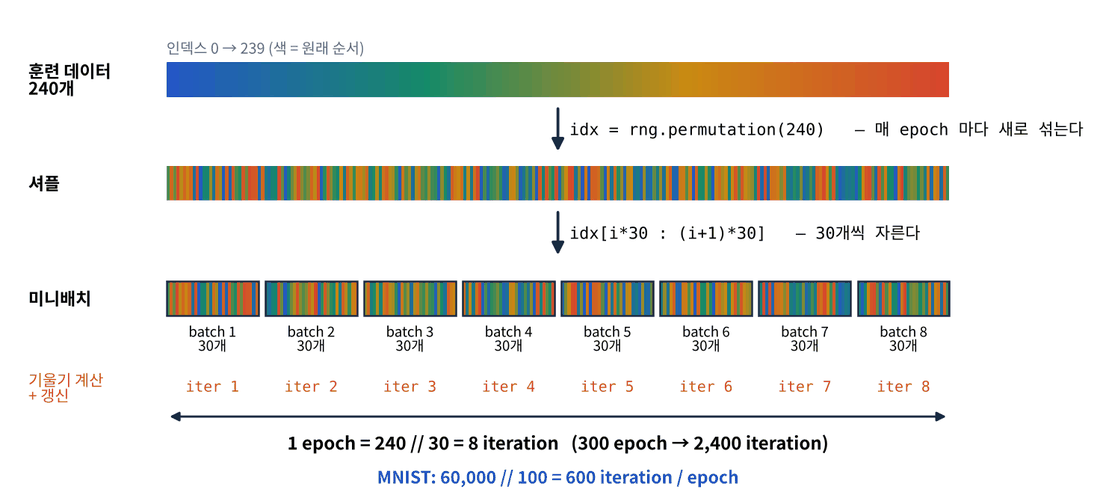

| 용어 | 뜻 | 나선 데이터 | MNIST (8교시) |
|---|---|---|---|
| batch size | 한 번 갱신에 쓰는 샘플 수 | 30 | 100 |
| iteration (step) | 미니배치 하나로 기울기 → 갱신 1회 | | |
| epoch | 학습 데이터 **전체를 한 바퀴** | 240 ÷ 30 = **8** iteration | 60,000 ÷ 100 = **600** iteration |
| 셔플 | 매 epoch 마다 순서를 섞음 (`rng.permutation`) | | |

- 매 epoch 섞는 이유: 같은 순서로 반복하면 미니배치 구성이 고정되어 기울기 추정이 한쪽으로 치우칠 수 있습니다.
- 미니배치 기울기는 전체 기울기의 **잡음 섞인 추정**입니다. 그래서 손실 곡선이 들쭉날쭉하지만, 평균적으로는 내려갑니다.
- **학습 데이터(train)** 로 학습하고, 학습에 쓰지 않은 **시험 데이터(test)** 의 정확도로 "처음 보는 데이터에도 통하는지"(일반화)를 확인합니다.

### 3 클래스 나선 데이터

직선 몇 개로는 나눌 수 없는, 세 갈래로 꼬인 데이터입니다. Day 2 의 로지스틱 회귀(직선 경계)로는 풀 수 없습니다.

In [ ]:
def make_spiral(n=100, k=3, seed=0):
    rng_ = np.random.default_rng(seed)
    X = np.zeros((n * k, 2)); t = np.zeros(n * k, dtype=int)
    for c in range(k):
        r_ = np.linspace(0.0, 1, n)
        th = np.linspace(c * 4, (c + 1) * 4, n) + rng_.normal(0, 0.2, n)
        X[c * n:(c + 1) * n] = np.c_[r_ * np.sin(th), r_ * np.cos(th)]
        t[c * n:(c + 1) * n] = c
    return X, t

Xsp, tsp = make_spiral()
p = np.random.default_rng(1).permutation(300)
X_tr, t_tr, X_te, t_te = Xsp[p[:240]], tsp[p[:240]], Xsp[p[240:]], tsp[p[240:]]
print("train", X_tr.shape, " test", X_te.shape)
plt.scatter(X_tr[:, 0], X_tr[:, 1], c=t_tr, cmap="brg", s=15); plt.axis("equal"); plt.title("spiral (train 240)"); plt.show()

**문제 7-1** 배치 크기 30 으로 300 epoch 학습할 때 epoch 당 iteration 수와 전체 iteration 수를 계산하세요.

In [ ]:
batch_size, epochs, lr = 30, 300, 1.0
iters_per_epoch = ____
total_iters = ____

In [ ]:
assert (iters_per_epoch, total_iters) == (8, 2400); print("✅ epoch 당", iters_per_epoch, "iteration, 전체", total_iters)

In [ ]:
#@title 🔒 정답 보기 7-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTEg4pSA4pSACmJhdGNoX3NpemUsIGVwb2NocywgbHIgPSAzMCwgMzAwLCAxLjAKaXRl"
    "cnNfcGVyX2Vwb2NoID0gbGVuKFhfdHIpIC8vIGJhdGNoX3NpemUKdG90YWxfaXRlcnMgPSBpdGVyc19wZXJfZXBv"
    "Y2ggKiBlcG9jaHM="
).decode("utf-8"))

**문제 7-2** 미니배치 SGD 학습 루프를 완성하세요.

1. epoch 마다 `rng7.permutation` 으로 인덱스를 섞는다.
2. 섞인 인덱스를 앞에서부터 `batch_size` 개씩 잘라 미니배치를 만든다.
3. 역전파로 기울기를 구하고 **제자리 갱신** `params[k] -= lr * grads[k]`.

In [ ]:
net7 = TwoLayerNet(2, 100, 3)
rng7 = np.random.default_rng(0)
hist7, snaps = [], {}
for epoch in range(1, epochs + 1):
    idx = ____
    for i in range(iters_per_epoch):
        batch = ____
        grads = ____
        for k in net7.params:
            net7.params[k] -= ____
    hist7.append((net7.loss(X_tr, t_tr), net7.accuracy(X_tr, t_tr), net7.accuracy(X_te, t_te)))
    if epoch in (1, 10, 50, 300):
        snaps[epoch] = {k: v.copy() for k, v in net7.params.items()}       # 결정 경계 그림용

In [ ]:
for ep in (1, 10, 50, 100, 200, 300):
    L_, a_tr, a_te = hist7[ep - 1]
    print(f"epoch {ep:3d}: loss {L_:.3f}  train {a_tr:.3f}  test {a_te:.3f}")
assert hist7[-1][1] >= 0.97 and hist7[-1][2] >= 0.95; print("✅")
h7 = np.array(hist7)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(h7[:, 0]); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("train loss"); ax[0].grid(alpha=.3)
ax[1].plot(h7[:, 1], label="train"); ax[1].plot(h7[:, 2], label="test"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("accuracy"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.show()

In [ ]:
#@title 🔒 정답 보기 7-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTIg4pSA4pSACm5ldDcgPSBUd29MYXllck5ldCgyLCAxMDAsIDMpCnJuZzcgPSBucC5y"
    "YW5kb20uZGVmYXVsdF9ybmcoMCkKaGlzdDcsIHNuYXBzID0gW10sIHt9CmZvciBlcG9jaCBpbiByYW5nZSgxLCBl"
    "cG9jaHMgKyAxKToKICAgIGlkeCA9IHJuZzcucGVybXV0YXRpb24obGVuKFhfdHIpKQogICAgZm9yIGkgaW4gcmFu"
    "Z2UoaXRlcnNfcGVyX2Vwb2NoKToKICAgICAgICBiYXRjaCA9IGlkeFtpICogYmF0Y2hfc2l6ZTooaSArIDEpICog"
    "YmF0Y2hfc2l6ZV0KICAgICAgICBncmFkcyA9IG5ldDcuZ3JhZGllbnQoWF90cltiYXRjaF0sIHRfdHJbYmF0Y2hd"
    "KQogICAgICAgIGZvciBrIGluIG5ldDcucGFyYW1zOgogICAgICAgICAgICBuZXQ3LnBhcmFtc1trXSAtPSBsciAq"
    "IGdyYWRzW2tdCiAgICBoaXN0Ny5hcHBlbmQoKG5ldDcubG9zcyhYX3RyLCB0X3RyKSwgbmV0Ny5hY2N1cmFjeShY"
    "X3RyLCB0X3RyKSwgbmV0Ny5hY2N1cmFjeShYX3RlLCB0X3RlKSkpCiAgICBpZiBlcG9jaCBpbiAoMSwgMTAsIDUw"
    "LCAzMDApOgogICAgICAgIHNuYXBzW2Vwb2NoXSA9IHtrOiB2LmNvcHkoKSBmb3IgaywgdiBpbiBuZXQ3LnBhcmFt"
    "cy5pdGVtcygpfSAgICAgICAjIOqysOyglSDqsr3qs4Qg6re466a87Jqp"
).decode("utf-8"))

**문제 7-3** 평면의 격자점마다 클래스를 예측해 결정 경계를 그리는 함수를 완성하세요. 저장해 둔 epoch 별 파라미터를 **제자리 복사**(`[...] =`)로 넣어 그 시점의 경계를 봅니다.

In [ ]:
def plot_boundary(net, ax, title):
    g = np.linspace(-1.1, 1.1, 200)
    G1, G2 = np.meshgrid(g, g)
    grid = np.c_[G1.ravel(), G2.ravel()]                 # (40000, 2)
    pred = ____
    ax.contourf(G1, G2, pred.reshape(G1.shape), alpha=0.25, cmap="brg")
    ax.scatter(X_tr[:, 0], X_tr[:, 1], c=t_tr, cmap="brg", s=8)
    ax.set_title(title); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    return pred

net_v = TwoLayerNet(2, 100, 3)
fig, axs = plt.subplots(1, 4, figsize=(15, 4))
for ax, ep in zip(axs, (1, 10, 50, 300)):
    for k in net_v.params:
        net_v.params[k][...] = snaps[ep][k]               # 제자리 복사 → Affine 계층과 연결 유지
    pred7 = plot_boundary(net_v, ax, f"epoch {ep}: test {hist7[ep - 1][2]:.2f}")
plt.show()

In [ ]:
assert pred7.shape == (40000,) and set(np.unique(pred7)) == {0, 1, 2}; print("✅ 300 epoch — 세 갈래 나선을 따라 굽은 경계")

In [ ]:
#@title 🔒 정답 보기 7-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTMg4pSA4pSACmRlZiBwbG90X2JvdW5kYXJ5KG5ldCwgYXgsIHRpdGxlKToKICAgIGcg"
    "PSBucC5saW5zcGFjZSgtMS4xLCAxLjEsIDIwMCkKICAgIEcxLCBHMiA9IG5wLm1lc2hncmlkKGcsIGcpCiAgICBn"
    "cmlkID0gbnAuY19bRzEucmF2ZWwoKSwgRzIucmF2ZWwoKV0gICAgICAgICAgICAgICAgICMgKDQwMDAwLCAyKQog"
    "ICAgcHJlZCA9IG5ldC5wcmVkaWN0KGdyaWQpLmFyZ21heChheGlzPTEpCiAgICBheC5jb250b3VyZihHMSwgRzIs"
    "IHByZWQucmVzaGFwZShHMS5zaGFwZSksIGFscGhhPTAuMjUsIGNtYXA9ImJyZyIpCiAgICBheC5zY2F0dGVyKFhf"
    "dHJbOiwgMF0sIFhfdHJbOiwgMV0sIGM9dF90ciwgY21hcD0iYnJnIiwgcz04KQogICAgYXguc2V0X3RpdGxlKHRp"
    "dGxlKTsgYXguc2V0X2FzcGVjdCgiZXF1YWwiKTsgYXguc2V0X3h0aWNrcyhbXSk7IGF4LnNldF95dGlja3MoW10p"
    "CiAgICByZXR1cm4gcHJlZAoKbmV0X3YgPSBUd29MYXllck5ldCgyLCAxMDAsIDMpCmZpZywgYXhzID0gcGx0LnN1"
    "YnBsb3RzKDEsIDQsIGZpZ3NpemU9KDE1LCA0KSkKZm9yIGF4LCBlcCBpbiB6aXAoYXhzLCAoMSwgMTAsIDUwLCAz"
    "MDApKToKICAgIGZvciBrIGluIG5ldF92LnBhcmFtczoKICAgICAgICBuZXRfdi5wYXJhbXNba11bLi4uXSA9IHNu"
    "YXBzW2VwXVtrXSAgICAgICAgICAgICAgICMg7KCc7J6Q66asIOuzteyCrCDihpIgQWZmaW5lIOqzhOy4teqzvCDs"
    "l7DqsrAg7Jyg7KeACiAgICBwcmVkNyA9IHBsb3RfYm91bmRhcnkobmV0X3YsIGF4LCBmImVwb2NoIHtlcH06IHRl"
    "c3Qge2hpc3Q3W2VwIC0gMV1bMl06LjJmfSIpCnBsdC5zaG93KCk="
).decode("utf-8"))

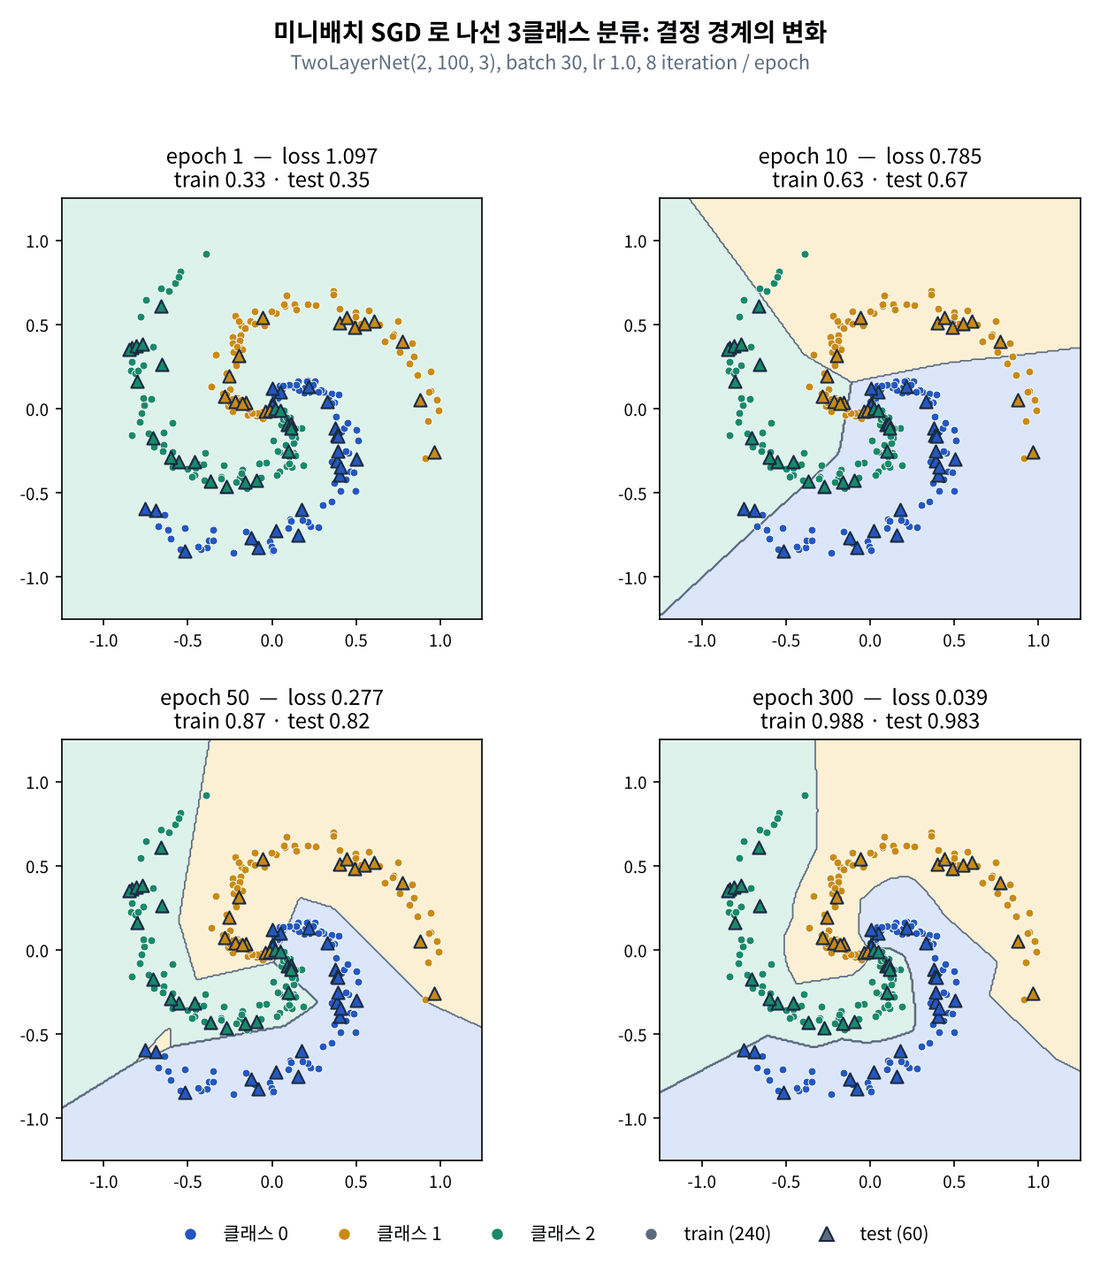

처음(epoch 1)에는 거의 한 클래스로 칠해지고, 학습이 진행될수록 경계가 **굽어지며** 나선을 따라갑니다. Day 2 의 로지스틱 회귀(직선 하나)와 달리, 은닉층 100개의 ReLU 가 만든 **꺾인 직선 조각들**이 모여 곡선 경계가 됩니다 (Day 2 4교시 "ReLU 를 넣으면 경계가 꺾인다").

손실 곡선이 중간(50~100 epoch)에 잠시 들쭉날쭉한 것은 미니배치 기울기의 잡음과 큰 학습률(1.0) 때문입니다 — Day 4 의 옵티마이저(Momentum · Adam)가 이 문제를 다룹니다.

#### ⚠️ 자주 하는 실수

- `net.params[k] = net.params[k] - lr * grads[k]` — 새 배열이 생겨 Affine 계층과 연결이 끊깁니다. 손실이 전혀 줄지 않으면 이것부터 확인하세요. `-=` 또는 `[...] =` 를 씁니다.
- `idx[i:i + batch_size]` — 시작 위치를 `i * batch_size` 로 곱하지 않으면 거의 같은 샘플만 반복해서 씁니다.
- 셔플한 인덱스로 `X` 만 자르고 `t` 는 원래 순서로 자름 — 입력과 정답이 어긋나 학습이 안 됩니다. 같은 `batch` 로 둘 다 자릅니다.
- test 데이터로 학습 — test 는 **평가에만** 씁니다.

#### 📌 7교시 정리

- 미니배치 SGD: epoch 마다 셔플 → batch 단위로 역전파 · 갱신. `iters_per_epoch = N // batch_size`.
- 미니배치 기울기는 전체 기울기의 잡음 섞인 추정 → 곡선은 들쭉날쭉하지만 내려간다.
- train 정확도로 학습 상태를, test 정확도로 일반화를 본다.
- 파라미터는 **제자리 갱신**.

## 8교시 — 미니 프로젝트: MNIST 2층 MLP

오늘 만든 계층 · 역전파 · 미니배치 SGD 로 **손글씨 숫자 0~9** 를 분류합니다. 28×28 흑백 이미지 6만 장으로 학습하고, 처음 보는 1만 장으로 평가합니다. 목표는 **test 정확도 95% 이상**입니다.

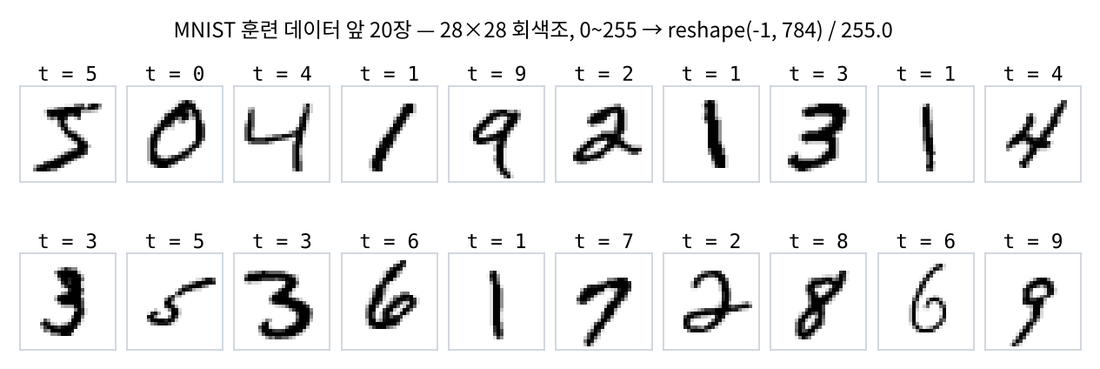

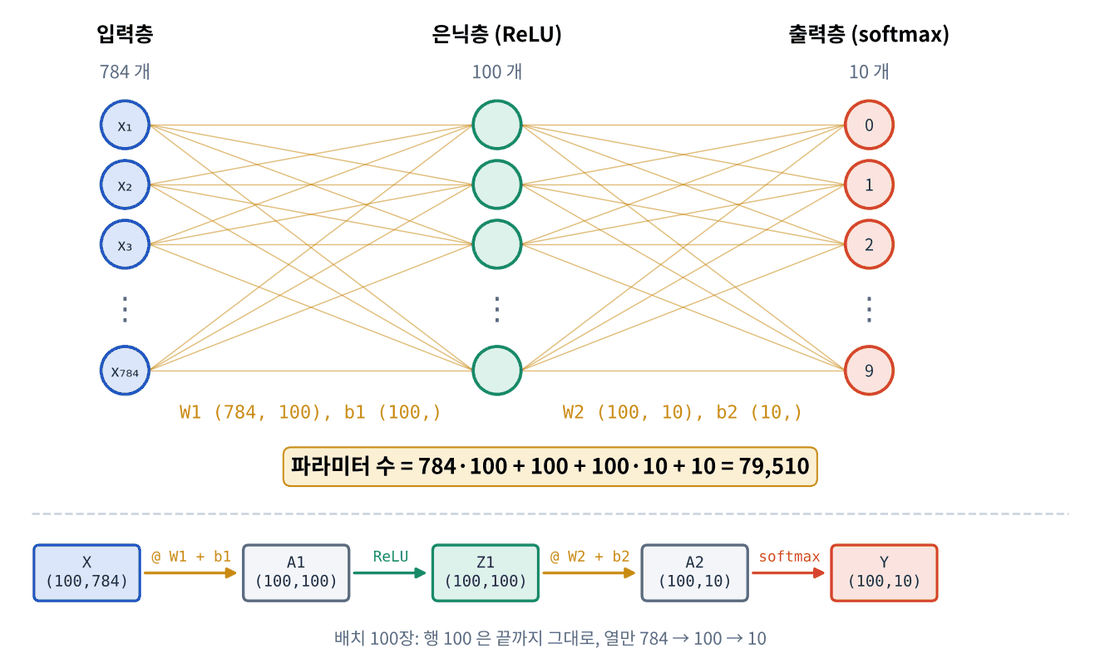

| 과제 | 내용 | 배점 |
|---|---|---|
| 1 | 전처리 — 펼치기 (N, 784) · 0~1 로 나누기 · 정수 레이블 | 20 |
| 2 | `TwoLayerNet(784, 100, 10)` 생성 · 학습 전 손실 | 20 |
| 3 | 미니배치 SGD 학습 루프 (10 epoch, **test ≥ 0.95**) | 30 |
| 4 | 학습 곡선 그리기 (손실 · train/test 정확도) | 20 |
| 5 | 결과 해석 (마크다운 답변) | 10 |

과제 끝의 **채점 셀**을 실행하면 자동 채점 점수가 나옵니다(과제 5 는 강사 채점). 학습은 Colab CPU 에서 30초~1분 정도 걸립니다.

> 🎬 **애니메이션** [D3-9 MNIST 2층 MLP](https://imguru-mooc.github.io/AI_CAMPUS/NN-day3/animation.html#d3-9)  
> 📝 **워크시트** [8교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day3/worksheet.html#t8)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

### 과제 1 — 전처리 (20점)

환경 셀에서 읽은 `x_train` 은 (60000, 28, 28) 크기의 `uint8` (0~255) 입니다. 신경망 입력으로 쓰려면

1. 한 장을 784 개짜리 행 하나로 **펼치고** — `reshape(-1, 784)`
2. 실수로 바꿔 **255 로 나눠** 0~1 범위로 맞추고 (값이 크면 학습이 불안정)
3. 레이블은 정수 배열로 둡니다 (`SoftmaxWithLoss` 가 레이블을 받음).

In [ ]:
X_train = ____
X_test = ____
t_train = y_train.astype(int)
t_test = ____

print(X_train.shape, X_test.shape, X_train.min(), X_train.max(), t_train[:10])

In [ ]:
#@title 🔒 정답 보기 8-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTEg4pSA4pSAClhfdHJhaW4gPSB4X3RyYWluLnJlc2hhcGUoLTEsIDc4NCkuYXN0eXBl"
    "KG5wLmZsb2F0NjQpIC8gMjU1LjAKWF90ZXN0ID0geF90ZXN0LnJlc2hhcGUoLTEsIDc4NCkuYXN0eXBlKG5wLmZs"
    "b2F0NjQpIC8gMjU1LjAKdF90cmFpbiA9IHlfdHJhaW4uYXN0eXBlKGludCkKdF90ZXN0ID0geV90ZXN0LmFzdHlw"
    "ZShpbnQpCgpwcmludChYX3RyYWluLnNoYXBlLCBYX3Rlc3Quc2hhcGUsIFhfdHJhaW4ubWluKCksIFhfdHJhaW4u"
    "bWF4KCksIHRfdHJhaW5bOjEwXSk="
).decode("utf-8"))

### 과제 2 — 네트워크 생성 · 학습 전 손실 (20점)

784-100-10 `TwoLayerNet` 을 만들고, 학습 전에 처음 100장의 손실을 계산하세요. 가중치가 0.01 배로 아주 작아 출력 점수가 거의 0 이므로, softmax 확률은 10개 클래스에 거의 **균등**(각 0.1)합니다. 그러면 손실은 얼마일까요?

In [ ]:
network = ____
loss0 = ____
print(f"학습 전 손실 {loss0:.4f}   vs   -log(0.1) = log 10 = {np.log(10):.4f}")

In [ ]:
#@title 🔒 정답 보기 8-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTIg4pSA4pSACm5ldHdvcmsgPSBUd29MYXllck5ldCg3ODQsIDEwMCwgMTApCmxvc3Mw"
    "ID0gbmV0d29yay5sb3NzKFhfdHJhaW5bOjEwMF0sIHRfdHJhaW5bOjEwMF0pCnByaW50KGYi7ZWZ7Iq1IOyghCDs"
    "hpDsi6Qge2xvc3MwOi40Zn0gICB2cyAgIC1sb2coMC4xKSA9IGxvZyAxMCA9IHtucC5sb2coMTApOi40Zn0iKQ=="
).decode("utf-8"))

### 과제 3 — 학습 루프 (30점)

7교시 루프를 MNIST 에 적용합니다. 학습률 0.1, 배치 100, **10 epoch** (6,000 iteration). iteration 마다 미니배치 손실(`network.lastLayer.loss` — `gradient()` 안의 순전파가 이미 계산해 둠)을 기록하고, epoch 마다 **train 전체**와 **test 전체**의 정확도를 기록합니다.

In [ ]:
lr, batch_size, epochs = 0.1, 100, 10
iters_per_epoch = ____
rng8 = np.random.default_rng(0)
loss_list, train_acc_list, test_acc_list = [], [], []

t_start = time.perf_counter()
for epoch in range(1, epochs + 1):
    idx = rng8.permutation(len(X_train))
    for i in range(iters_per_epoch):
        batch = idx[i * batch_size:(i + 1) * batch_size]
        grads = ____
        for k in network.params:
            network.params[k] -= ____
        loss_list.append(____)
    train_acc_list.append(network.accuracy(X_train, t_train))
    test_acc_list.append(____)
    print(f"epoch {epoch:2d}  train {train_acc_list[-1]:.4f}  test {test_acc_list[-1]:.4f}  "
          f"loss {np.mean(loss_list[-iters_per_epoch:]):.3f}  ({time.perf_counter() - t_start:.0f} s)")

In [ ]:
#@title 🔒 정답 보기 8-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTMg4pSA4pSACmxyLCBiYXRjaF9zaXplLCBlcG9jaHMgPSAwLjEsIDEwMCwgMTAKaXRl"
    "cnNfcGVyX2Vwb2NoID0gbGVuKFhfdHJhaW4pIC8vIGJhdGNoX3NpemUKcm5nOCA9IG5wLnJhbmRvbS5kZWZhdWx0"
    "X3JuZygwKQpsb3NzX2xpc3QsIHRyYWluX2FjY19saXN0LCB0ZXN0X2FjY19saXN0ID0gW10sIFtdLCBbXQoKdF9z"
    "dGFydCA9IHRpbWUucGVyZl9jb3VudGVyKCkKZm9yIGVwb2NoIGluIHJhbmdlKDEsIGVwb2NocyArIDEpOgogICAg"
    "aWR4ID0gcm5nOC5wZXJtdXRhdGlvbihsZW4oWF90cmFpbikpCiAgICBmb3IgaSBpbiByYW5nZShpdGVyc19wZXJf"
    "ZXBvY2gpOgogICAgICAgIGJhdGNoID0gaWR4W2kgKiBiYXRjaF9zaXplOihpICsgMSkgKiBiYXRjaF9zaXplXQog"
    "ICAgICAgIGdyYWRzID0gbmV0d29yay5ncmFkaWVudChYX3RyYWluW2JhdGNoXSwgdF90cmFpbltiYXRjaF0pCiAg"
    "ICAgICAgZm9yIGsgaW4gbmV0d29yay5wYXJhbXM6CiAgICAgICAgICAgIG5ldHdvcmsucGFyYW1zW2tdIC09IGxy"
    "ICogZ3JhZHNba10KICAgICAgICBsb3NzX2xpc3QuYXBwZW5kKG5ldHdvcmsubGFzdExheWVyLmxvc3MpCiAgICB0"
    "cmFpbl9hY2NfbGlzdC5hcHBlbmQobmV0d29yay5hY2N1cmFjeShYX3RyYWluLCB0X3RyYWluKSkKICAgIHRlc3Rf"
    "YWNjX2xpc3QuYXBwZW5kKG5ldHdvcmsuYWNjdXJhY3koWF90ZXN0LCB0X3Rlc3QpKQogICAgcHJpbnQoZiJlcG9j"
    "aCB7ZXBvY2g6MmR9ICB0cmFpbiB7dHJhaW5fYWNjX2xpc3RbLTFdOi40Zn0gIHRlc3Qge3Rlc3RfYWNjX2xpc3Rb"
    "LTFdOi40Zn0gICIKICAgICAgICAgIGYibG9zcyB7bnAubWVhbihsb3NzX2xpc3RbLWl0ZXJzX3Blcl9lcG9jaDpd"
    "KTouM2Z9ICAoe3RpbWUucGVyZl9jb3VudGVyKCkgLSB0X3N0YXJ0Oi4wZn0gcykiKQ=="
).decode("utf-8"))

### 과제 4 — 학습 곡선 (20점)

왼쪽에 iteration 별 미니배치 손실, 오른쪽에 epoch 별 train · test 정확도를 그리세요. 오른쪽에는 목표선 0.95 도 그립니다. 그림 객체는 `fig4` 에 담습니다 (채점에 사용).

In [ ]:
fig4, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(____, lw=0.5, alpha=0.6, label="mini-batch loss")
ax[0].set_xlabel("iteration"); ax[0].set_ylabel("loss"); ax[0].grid(alpha=.3); ax[0].legend()

ep_axis = np.arange(1, epochs + 1)
ax[1].plot(ep_axis, ____, "o-", label="train")
ax[1].plot(ep_axis, ____, "s--", label="test")
ax[1].axhline(0.95, color="gray", ls=":", label="target 0.95")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("accuracy"); ax[1].grid(alpha=.3); ax[1].legend()
plt.show()

In [ ]:
#@title 🔒 정답 보기 8-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTQg4pSA4pSACmZpZzQsIGF4ID0gcGx0LnN1YnBsb3RzKDEsIDIsIGZpZ3NpemU9KDEy"
    "LCA0KSkKYXhbMF0ucGxvdChsb3NzX2xpc3QsIGx3PTAuNSwgYWxwaGE9MC42LCBsYWJlbD0ibWluaS1iYXRjaCBs"
    "b3NzIikKYXhbMF0uc2V0X3hsYWJlbCgiaXRlcmF0aW9uIik7IGF4WzBdLnNldF95bGFiZWwoImxvc3MiKTsgYXhb"
    "MF0uZ3JpZChhbHBoYT0uMyk7IGF4WzBdLmxlZ2VuZCgpCgplcF9heGlzID0gbnAuYXJhbmdlKDEsIGVwb2NocyAr"
    "IDEpCmF4WzFdLnBsb3QoZXBfYXhpcywgdHJhaW5fYWNjX2xpc3QsICJvLSIsIGxhYmVsPSJ0cmFpbiIpCmF4WzFd"
    "LnBsb3QoZXBfYXhpcywgdGVzdF9hY2NfbGlzdCwgInMtLSIsIGxhYmVsPSJ0ZXN0IikKYXhbMV0uYXhobGluZSgw"
    "Ljk1LCBjb2xvcj0iZ3JheSIsIGxzPSI6IiwgbGFiZWw9InRhcmdldCAwLjk1IikKYXhbMV0uc2V0X3hsYWJlbCgi"
    "ZXBvY2giKTsgYXhbMV0uc2V0X3lsYWJlbCgiYWNjdXJhY3kiKTsgYXhbMV0uZ3JpZChhbHBoYT0uMyk7IGF4WzFd"
    "LmxlZ2VuZCgpCnBsdC5zaG93KCk="
).decode("utf-8"))

### 과제 5 — 결과 해석 (10점)

아래 셀에 답을 쓰세요.

1. 학습 전 손실이 약 2.30 이었던 이유는? (힌트: 균등한 확률, $-\log$)
2. 마지막 epoch 에서 train 정확도가 test 보다 조금 높습니다. 이 차이는 무엇을 뜻하고, 차이가 크게 벌어지면 어떤 문제일까요?
3. 같은 학습을 1교시의 수치 미분으로 했다면 대략 얼마나 걸렸을까요? 역전파가 빠른 이유를 계산 그래프 관점에서 한 문장으로 쓰세요.

✍️ *여기에 답을 쓰세요.*

In [ ]:
#@title 🔒 해설 보기 8교시 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIO2VtOyEpCDilIDilIAKMS4g6rCA7KSR7LmY6rCAIOyekeyVhCgwLjAxIOuwsCkg7Lac66ClIOygkOyI"
    "mOqwgCDqsbDsnZggMCDsnbTrqbQgc29mdG1heCDtmZXrpaDsnYAgMTDqsJwg7YG0656Y7Iqk7JeQIOqxsOydmCDq"
    "t6Drk7HtlZjqsowgMC4xIOyUqeyeheuLiOuLpC4gY3Jvc3MtZW50cm9weSA9IOKIkmxvZyjsoJXri7Ug7ZmV66Wg"
    "KSA9IOKIkmxvZyAwLjEgPSBsb2cgMTAg4omIIDIuMzAyNi4g7ZWZ7Iq1IOyghCDshpDsi6TsnbQg7J20IOqwkuqz"
    "vCDtgazqsowg64uk66W066m0IOy0iOq4sO2ZlOuCmCDshpDsi6Qg6rWs7ZiE7J2EIOydmOyLrO2VtOyVvCDtlanr"
    "i4jri6Qo7Jyg7Jqp7ZWcIOygkOqygOuylSkuCjIuIOuqqOuNuOydtCDtlZnsirUg642w7J207YSw7JeQIOyhsOq4"
    "iCDrjZQg66ee7Law7KC4IOyeiOuLpOuKlCDrnLvsnoXri4jri6Qo7J2867CY7ZmUIOqwhOq3uSkuIOyngOq4iOyd"
    "gCAwLjUlcCDsoJXrj4Trnbwg6rSc7LCu7KeA66eMLCDtlZnsirUg642w7J207YSw6rCAIOyggeqxsOuCmCDrqqjr"
    "jbjsnbQg7YGs6rGw64KYIOyYpOuemCDtlZnsirXtlZjrqbQgdHJhaW4g7J2AIOqzhOyGjSDsmKTrpbTqs6AgdGVz"
    "dCDripQg66mI7LaU6rGw64KYIOuWqOyWtOyngOuKlCDqs7zsoIHtlakob3ZlcmZpdHRpbmcp7J20IOuQqeuLiOuL"
    "pCDigJQgRGF5IDQg7J2YIHdlaWdodCBkZWNheSDCtyBEcm9wb3V0IOycvOuhnCDri6Tro7nri4jri6QuCjMuIDHq"
    "tZDsi5wg7LaU7KCV7Jy866GcIHN0ZXAg64u5IOyImOyLrSDstIggw5cgNiwwMDAgc3RlcCDiiYgg7IiY7IutfjEw"
    "MCDsi5zqsIQg7J207IOBLiDsl63soITtjIzripQg7Iic7KCE7YyMIOuVjCDsoIDsnqXtlZwg7KSR6rCE6rCS7J2E"
    "IOyerOyCrOyaqe2VmOupsCDstpzroKXsl5DshJwg7J6F66ClIOuwqe2WpeycvOuhnCDqta3showg66+467aE7J2E"
    "IO2VnCDrsojslKnrp4wg6rOx7ZW0LCDsiJzsoITtjIwg7ZWcIOuyiCArIOyXreuwqe2WpSDtlZwg67KI7Jy866Gc"
    "IOuqqOuToCDtjIzrnbzrr7jthLDsnZgg6riw7Jq46riw66W8IOuPmeyLnOyXkCDqtaztlZjquLAg65WM66y47J6F"
    "64uI64ukLg=="
).decode("utf-8"))

### 채점 셀

In [ ]:
score = 0
try:
    assert X_train.shape == (60000, 784) and X_test.shape == (10000, 784)
    assert X_train.dtype.kind == "f" and 0.0 <= X_train.min() and X_train.max() <= 1.0 and X_train.max() > 0.9
    assert t_train.dtype.kind == "i" and t_test.shape == (10000,)
    score += 20; print("✅ 과제 1  +20")
except Exception as e: print("❌ 과제 1", e)
try:
    assert network.params["W1"].shape == (784, 100) and network.params["W2"].shape == (100, 10)
    assert abs(loss0 - np.log(10)) < 0.05
    score += 20; print("✅ 과제 2  +20")
except Exception as e: print("❌ 과제 2", e)
try:
    assert len(loss_list) == epochs * iters_per_epoch and len(test_acc_list) == epochs
    assert np.mean(loss_list[-100:]) < np.mean(loss_list[:100])
    assert test_acc_list[-1] >= 0.95 and abs(network.accuracy(X_test, t_test) - test_acc_list[-1]) < 1e-9
    score += 30; print(f"✅ 과제 3  +30   (test {test_acc_list[-1]:.4f})")
except Exception as e: print("❌ 과제 3", e)
try:
    assert len(fig4.axes) >= 2 and len(fig4.axes[0].lines) >= 1 and len(fig4.axes[1].lines) >= 2
    assert len(fig4.axes[0].lines[0].get_ydata()) == len(loss_list)
    score += 20; print("✅ 과제 4  +20")
except Exception as e: print("❌ 과제 4", e)
print(f"\n자동 채점 {score} / 90  (과제 5 는 강사 채점 10점)")

### 🔎 더 알아보기 — 학습된 신경망 들여다보기

과제를 제출한 뒤에 보세요.

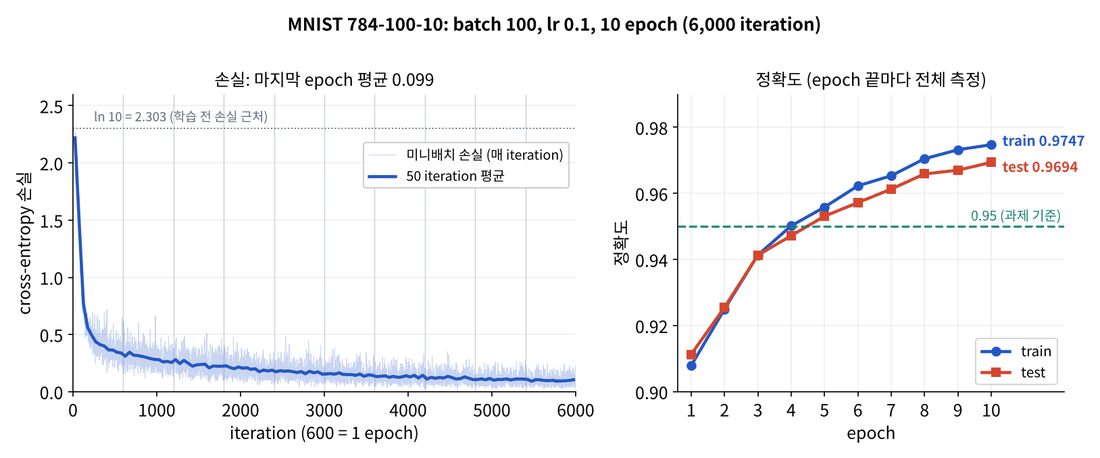

위 그림은 이 노트북과 같은 설정(seed 0)으로 학습한 기준 결과입니다 — 10 epoch 후 train 0.9747, test **0.9694**. 여러분의 숫자가 소수 넷째 자리까지 같지 않아도 괜찮습니다 (CPU 종류에 따라 행렬곱의 반올림이 미세하게 다름).

### 틀린 숫자 보기

test 1만 장 중 약 300장을 틀립니다. 어떤 숫자를 틀리는지 직접 보세요 — 사람이 봐도 헷갈리는 글씨가 많습니다.

In [ ]:
pred = network.predict(X_test).argmax(axis=1)
wrong = np.where(pred != t_test)[0]
print(f"틀린 개수 {len(wrong)} / {len(t_test)}")
fig, axs = plt.subplots(2, 8, figsize=(14, 4))
for ax, i in zip(axs.ravel(), wrong[:16]):
    ax.imshow(x_test[i], cmap="gray_r"); ax.set_title(f"t={t_test[i]} p={pred[i]}", fontsize=10); ax.axis("off")
plt.show()

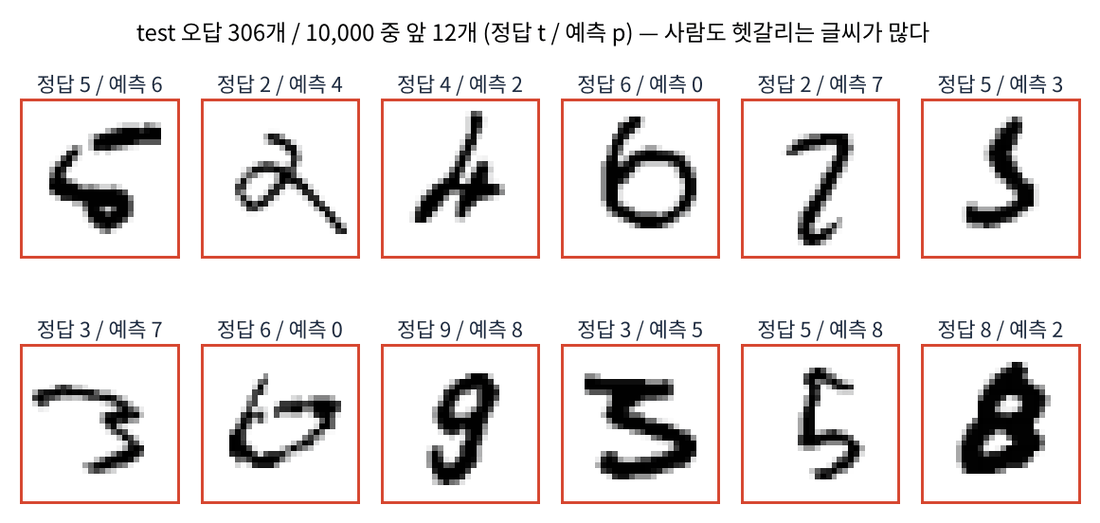

### 온디바이스 맛보기 — 가중치를 int8 로 줄이면?

학습된 가중치는 float64(8바이트)입니다. 각 행렬을 −127 ~ 127 정수(int8, 1바이트)로 바꾸고 추론 때 다시 곱해 쓰면 메모리는 1/8 이 됩니다. 정확도는 얼마나 떨어질까요? 이것이 Vision 과정 이후에 다룰 **Quantization(양자화)** 의 핵심 아이디어입니다.

In [ ]:
def quantize(W):
    scale = np.abs(W).max() / 127
    return np.round(W / scale).astype(np.int8), scale

q = {k: quantize(v) for k, v in network.params.items()}
Wq = {k: qv.astype(np.float64) * s for k, (qv, s) in q.items()}       # 추론 때 되돌려 쓰기
H = np.maximum(0, X_test @ Wq["W1"] + Wq["b1"])
acc_q = np.mean((H @ Wq["W2"] + Wq["b2"]).argmax(axis=1) == t_test)
mem = sum(v.nbytes for v in network.params.values()); mem_q = sum(qv.nbytes for qv, _ in q.values())
print(f"float64 {mem / 1024:.0f} KB, test {test_acc_list[-1]:.4f}  →  int8 {mem_q / 1024:.0f} KB, test {acc_q:.4f}")

In [ ]:
# (선택) 학습한 가중치를 Drive 에 저장 — Day 4 에서 이어 쓸 수 있습니다
save_dir = "/content/drive/MyDrive/NN_course"
if os.path.isdir("/content/drive/MyDrive"):
    os.makedirs(save_dir, exist_ok=True)
    np.savez(f"{save_dir}/day3_mnist_mlp.npz", **network.params)
    print("저장:", f"{save_dir}/day3_mnist_mlp.npz")
else:
    print("Drive 가 연결되지 않아 저장을 건너뜁니다")

## 오늘의 정리

### 셀프 체크

- [ ] 수치 미분이 $O(P^2)$, 역전파가 $O(P)$ 인 이유를 설명할 수 있다
- [ ] 계산 그래프에서 순전파 값과 역전파 기울기를 손으로 채울 수 있다 (사과 · 귤 715 → 2.2, 110, 3.3, 165, 650)
- [ ] 덧셈 노드(그대로)와 곱셈 노드(바꿔 곱함)의 역전파를 연쇄 법칙으로 설명할 수 있다
- [ ] `Relu`(mask) · `Sigmoid`(out) 계층이 forward 에서 무엇을 저장하는지 말할 수 있다
- [ ] Affine 의 `dX = dout @ W.T`, `dW = X.T @ dout`, `db = dout.sum(axis=0)` 를 shape 로 유도할 수 있다
- [ ] Softmax-with-Loss 의 기울기가 $(Y - T)/N$ 이고, Day 2 의 손 유도 기울기와 같음을 확인했다
- [ ] gradient check 로 상대 오차 < 1e-7 을 확인하고, shape 가 맞아도 틀리는 버그를 찾을 수 있다
- [ ] 미니배치 SGD 의 epoch · batch · iteration 과 셔플 · 제자리 갱신을 구현할 수 있다
- [ ] MNIST 784-100-10 을 학습시켜 test 95% 이상을 얻었다

### 내일 (Day 4) 예고 — 학습 기법

오늘 나선 데이터의 손실 곡선이 중간에 흔들렸고, MNIST 도 10 epoch 이 걸렸습니다. 내일은 **더 빨리, 더 안정적으로, 과적합 없이** 학습시키는 방법을 직접 구현합니다: SGD 의 약점 → **Momentum · AdaGrad · RMSProp · Adam**, **Xavier · He 초기화** (오늘 쓴 0.01 은 왜 문제인가), **Batch Normalization**, **weight decay · Dropout**, 하이퍼파라미터 탐색. 마지막에는 오늘의 계층 클래스와 옵티마이저를 `Sequential` · `Trainer` 로 묶은 미니 프레임워크 `mynn.py` 를 완성합니다.